# WM-811K 분할 전 EDA

canonical 구조·품질을 로컬에서 확인합니다. 원본 pickle, 라벨 수정, 충돌 제외, 분할, resize, 증강, 모델 학습은 실행하지 않습니다.

노트북·CLI와 등록 모듈 `wm_canonical_eda`는 `src/wafer_dl/eda.py`의 같은 코어를 사용합니다. 등록 모듈은 승인된 WM 단독 worker 경로이며, 통합 작업의 웨이퍼 입력 연결이나 LLM의 직접 도구 실행은 지원하지 않습니다.

**출력에는 실제 집계·이미지가 포함됩니다. LLM·외부 추적에 보내지 말고 Git 공유 전 모든 셀 출력을 지우세요.** 전체 데이터 EDA는 구조·품질 확인용입니다. 입력 해상도·증강 선택은 분할 후 Train/Validation에서 진행합니다.

먼저 canonical 정합성 검사를 통과한 묶음을 사용하세요. EDA는 전체 NPZ 정합성 검사를 대신하지 않습니다.

11절은 현재 모델 실험의 저장 결과만 읽습니다. 학습·재추론·Test 평가는 이 노트북에서 실행하지 않습니다.

In [1]:
# ==========================================
# 노트북 실행 위치와 무관하게 프로젝트 루트 확인
# - 작업 폴더는 변경하지 않고 import 경로만 추가
# - 코어는 원본 pickle을 읽지 않음
# ==========================================
from pathlib import Path
import sys
import json

project_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/wafer_dl/eda.py').is_file()), None)
if project_root is None:
    raise RuntimeError('프로젝트 내부에서 노트북을 실행하세요.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from IPython.display import display
import matplotlib.pyplot as plt
from src.wafer_dl.eda import (
    load_eda_metadata, summarize_metadata, select_example_positions,
    load_example_maps, plot_distributions, plot_die_statistics, plot_examples, run_eda,
)
print('공통 EDA 코어 준비 완료. 아직 데이터를 읽지 않았습니다.')

공통 EDA 코어 준비 완료. 아직 데이터를 읽지 않았습니다.


## 1. 새 canonical 묶음 선택

`CANONICAL_DIR`에 실제 폴더 경로를 입력할 수 있습니다. `None`이면 수정 라벨 버전의 후보가 하나일 때만 자동 선택합니다. 여러 후보에서 최신 폴더를 임의로 선택하지 않습니다.

In [2]:
# 실제 폴더를 직접 선택하려면 None 대신 경로 문자열을 넣으세요.
CANONICAL_DIR = None

if CANONICAL_DIR is None:
    base = project_root / 'data/processed/wm811k/canonical'
    candidates = []
    from src.wafer_dl.validate_canonical import read_json
    for folder in sorted(base.glob('canonical_*')):
        if folder.is_dir() and (folder / 'SUCCESS.json').is_file():
            if read_json(folder / 'conversion.json').get('label_normalization_version') == 'wm_label_v2':
                candidates.append(folder)
    if len(candidates) != 1:
        print('수정 버전 후보 폴더:', [p.name for p in candidates])
        raise ValueError('후보가 하나가 아닙니다. CANONICAL_DIR에 실제 폴더를 지정하세요.')
    canonical_dir = candidates[0]
else:
    canonical_dir = Path(CANONICAL_DIR)
    if not canonical_dir.is_absolute():
        canonical_dir = project_root / canonical_dir

metadata = load_eda_metadata(canonical_dir)
tables = summarize_metadata(metadata)
print('metadata 집계 완료. 맵 배열은 아직 읽지 않았습니다.')

metadata 집계 완료. 맵 배열은 아직 읽지 않았습니다.


## 2. 클래스·미라벨·격리·중복 요약

- `labeled_samples`와 `accepted_labeled_samples`를 구분합니다. 
- 미라벨은 정상 `None`으로 취급하지 않습니다. 
- 같은 맵 내용의 중복은 같은 실물 웨이퍼의 복제라고 단정할 수 없습니다. 
- Lot 수는 독립 연결 그룹 수와 다릅니다. 
- 연결 그룹 상세 진단은 `diagnose_split` 보고서를 함께 보세요.

In [3]:
display(tables['classes'])
display(tables['statuses'])
display(tables['statistics'])
display(tables['shapes'].head(20))
display(tables['lot_sizes'].describe())

,labeled_samples,accepted_labeled_samples,accepted_lot_count
pattern_label,,,
None,147431,147431,6591
Center,4294,4294,1648
Donut,555,555,233
Edge-Loc,5189,5189,3211
Edge-Ring,9680,9680,1075
Loc,3593,3593,2472
Near-Full,149,149,137
Random,866,866,449
Scratch,1193,1193,1059


,,rows
label_status,quality_status,
labeled,accepted,172950
unlabeled,accepted,638507


{'row_count': 811457,
 'rows_with_valid_map': 811457,
 'lot_count': 46293,
 'duplicate_map_groups': 32630,
 'rows_in_duplicate_groups': 147488,
 'map_label_conflict_groups': 14,
 'split_complete': False,
 'training_ready': False}

,map_height,map_width,rows
88,32,29,108687
34,25,27,64083
255,49,39,39323
38,26,26,30078
77,30,34,29513
102,33,33,23886
98,33,29,20276
162,39,37,15327
292,52,59,14812
84,31,31,14569


count    46293.000000
mean        17.528719
std          8.964477
min          1.000000
25%         10.000000
50%         24.000000
75%         25.000000
max         25.000000
Name: rows_per_lot, dtype: float64

## 3. 분포 그림

- 클래스·상태 건수는 로그축으로 다수/희소 그룹을 함께 확인합니다. 
- 맵 크기·종횡비는 resize 전 구조입니다. 
- 불량 다이 비율은 유효 다이 중 값 2의 비율이며 SECOM 불량 확률과 다릅니다.

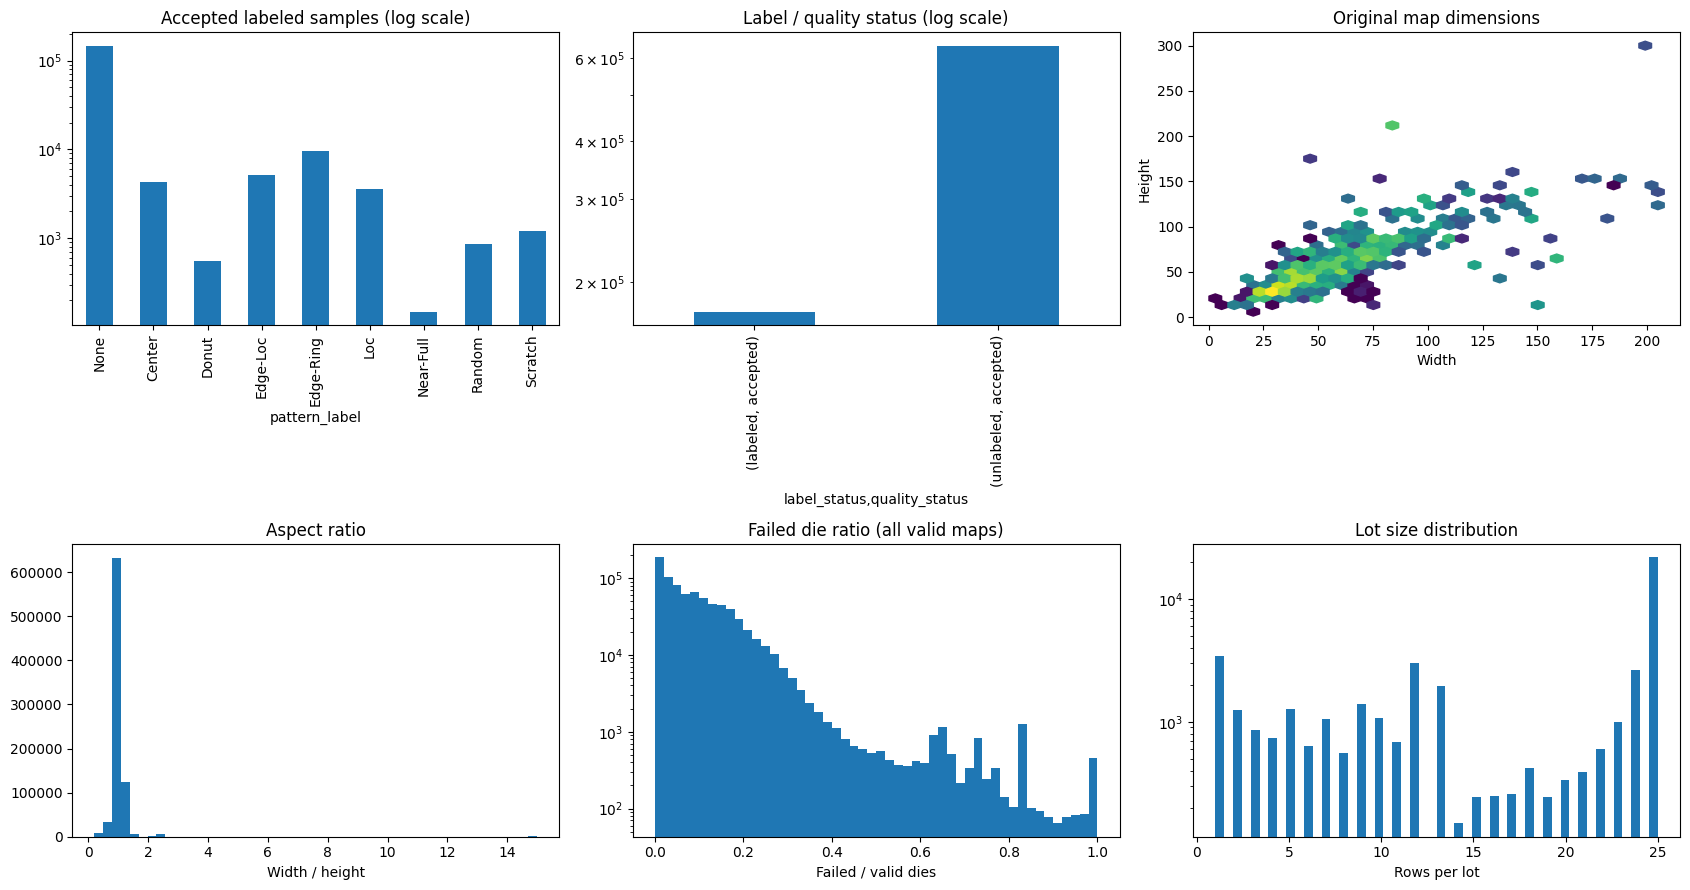

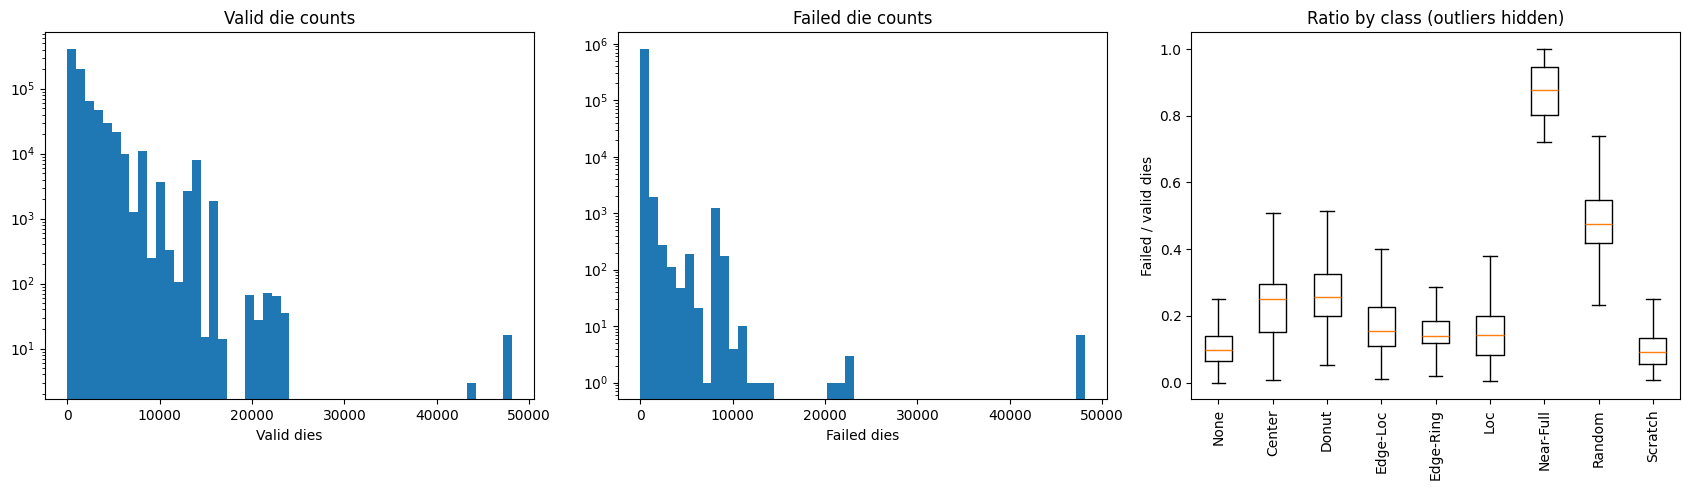

In [4]:
figure = plot_distributions(metadata, tables)
plt.show()
plt.close(figure)
figure = plot_die_statistics(metadata)
plt.show()
plt.close(figure)

## 4. 수치 metadata 상관분석

- accepted 유효 맵의 완전 관측 행(미라벨 포함)으로 Spearman·Pearson을 비교합니다. 
- 클래스 번호·Lot·해시·행 번호는 제외합니다.
- 상수 열·3건 미만은 N/A입니다. 
- 전체 계수는 클래스 구성·중복·Lot의 영향을 받으며 독립 표본 검정이 아닙니다.
- 불량 비율=불량 다이 수/유효 다이 수이므로 계산상 연관에 주의하세요. 
- 상관은 인과관계나 자동 특징 선택 근거가 아닙니다. 모델용 선택은 분할 후 Train에서 검토합니다.
- 산점도만 최대 5,000건을 고정 추출하며 클래스 균형 표본이 아닙니다. 
- 표·그림은 로컬 전용입니다.

,rows
all_accepted,811457


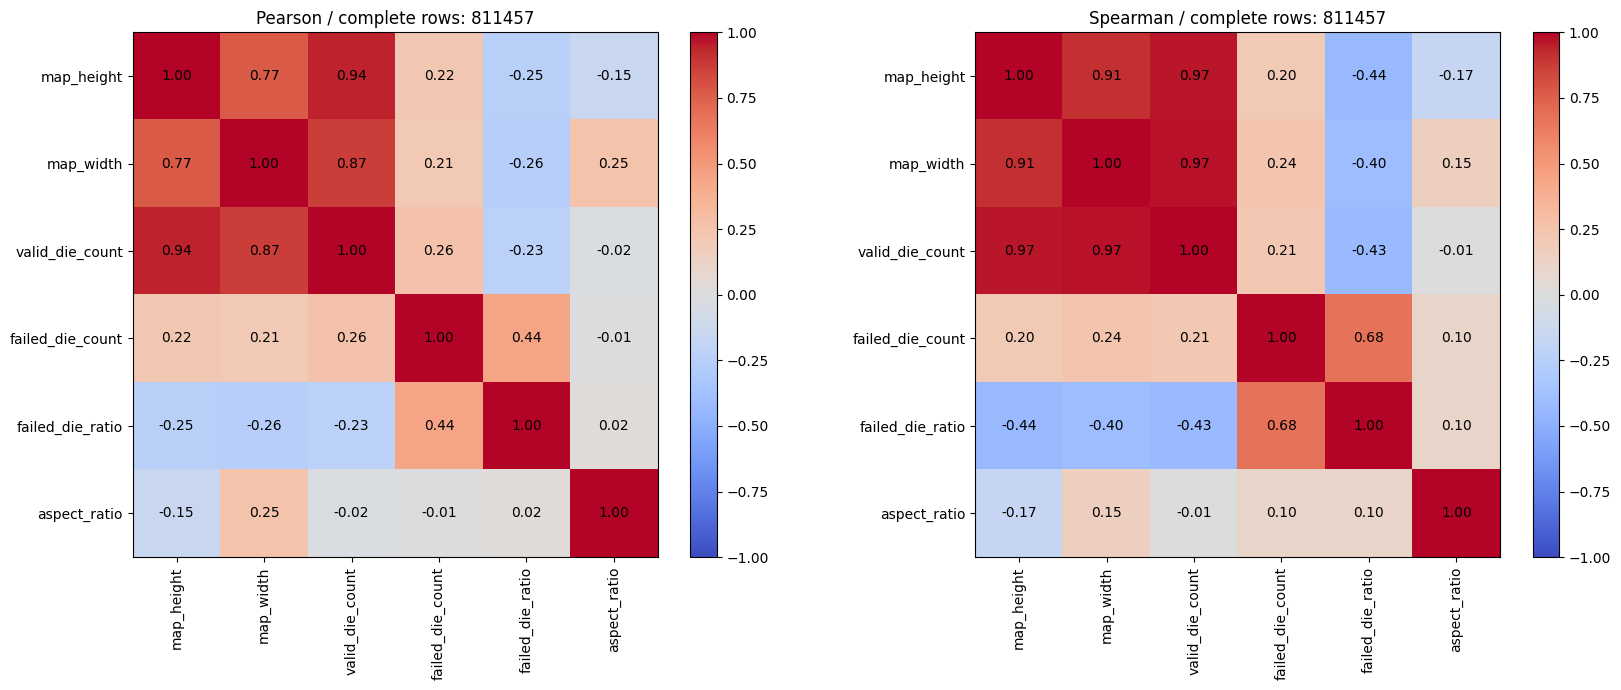

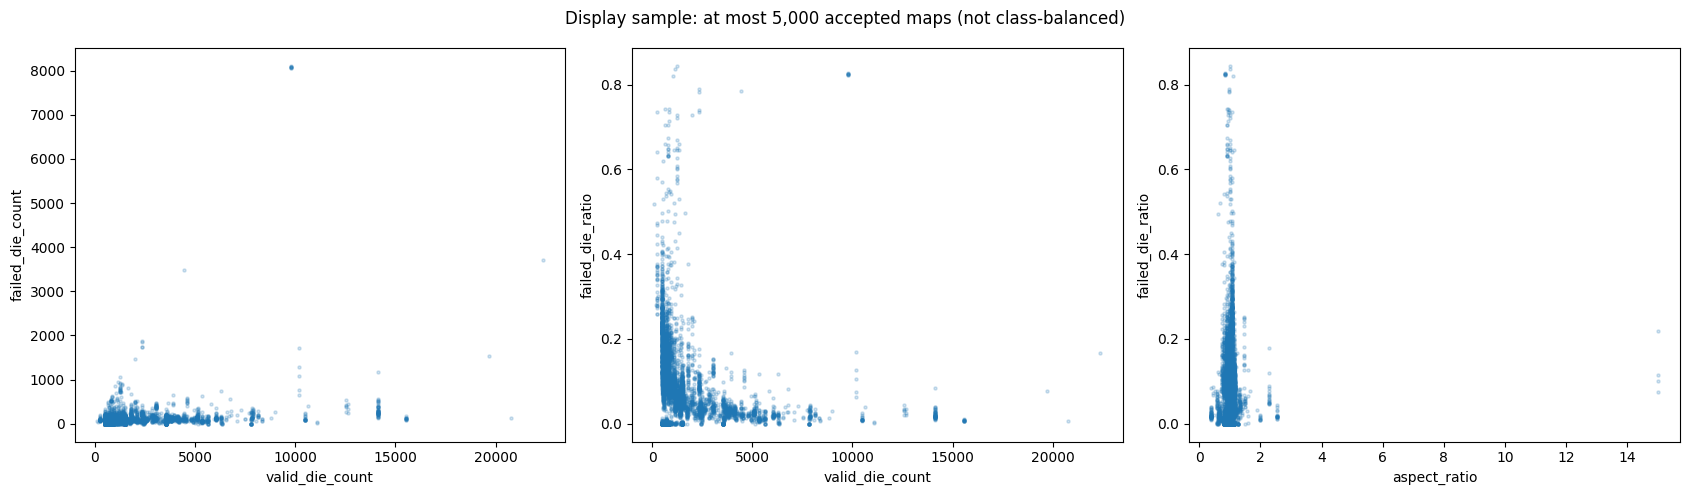

,pattern_label,method,first,second,rows,correlation
10,None,pearson,valid_die_count,failed_die_ratio,147431,-0.444934
25,None,spearman,valid_die_count,failed_die_ratio,147431,-0.703998
40,Center,pearson,valid_die_count,failed_die_ratio,4294,-0.389056
55,Center,spearman,valid_die_count,failed_die_ratio,4294,-0.596383
70,Donut,pearson,valid_die_count,failed_die_ratio,555,0.224154
85,Donut,spearman,valid_die_count,failed_die_ratio,555,0.127126
100,Edge-Loc,pearson,valid_die_count,failed_die_ratio,5189,-0.278933
115,Edge-Loc,spearman,valid_die_count,failed_die_ratio,5189,-0.517977
130,Edge-Ring,pearson,valid_die_count,failed_die_ratio,9680,-0.631286
145,Edge-Ring,spearman,valid_die_count,failed_die_ratio,9680,-0.770132


In [5]:
from src.wafer_dl.eda import summarize_correlations, plot_correlations, plot_correlation_scatter

# 전체 적격 행의 계수와 클래스별 표본 수를 확인합니다.
correlations = summarize_correlations(metadata)
display(correlations['support'])
figure = plot_correlations(correlations)
plt.show()
plt.close(figure)
figure = plot_correlation_scatter(metadata)
plt.show()
plt.close(figure)
# 우선 유효 다이 수와 불량 비율의 관계를 클래스별로 비교합니다.
class_correlations = correlations['by_class']
display(class_correlations.loc[
    class_correlations['first'].eq('valid_die_count') &
    class_correlations['second'].eq('failed_die_ratio')
])

## 5. 클래스별 원본 크기 예시

- 회색=웨이퍼 밖(0), 초록=정상 다이(1), 빨강=불량 다이(2). 
- 클래스별 첫 유효 1건만 확인하며 대표성이나 클래스 전체 특성을 보장하지 않습니다. 
- 이 셀만 소수의 NPZ 배열을 숫자 전용으로 읽습니다. 
- 예시를 보고 Test용 변환 설정을 최적화하지 않습니다.

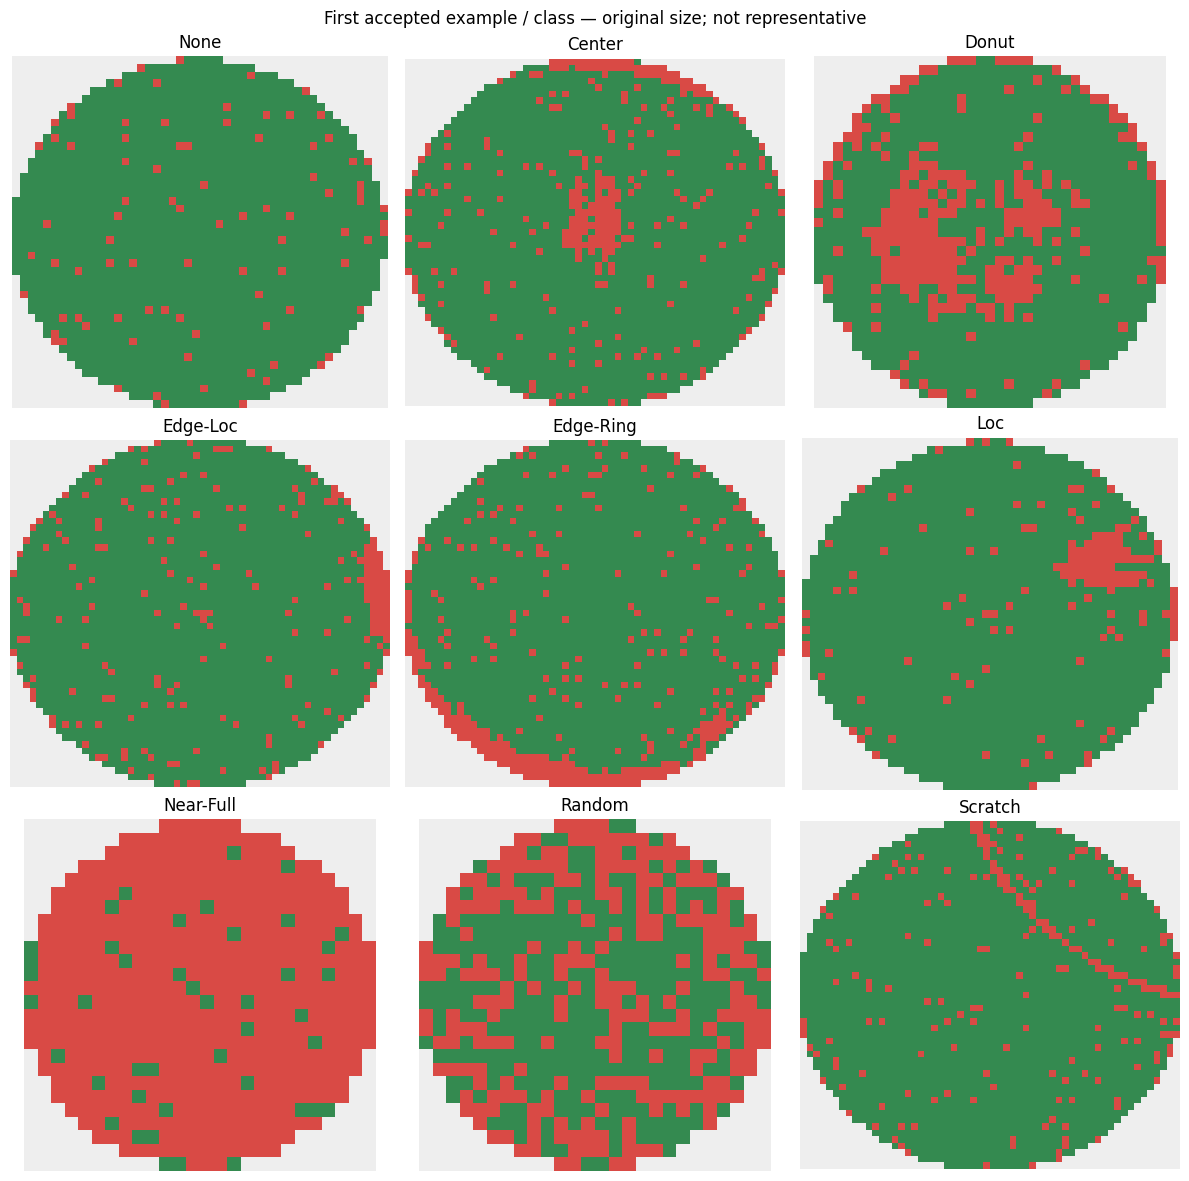

In [6]:
positions = select_example_positions(metadata)
examples = load_example_maps(canonical_dir, positions)
figure = plot_examples(examples)
plt.show()
plt.close(figure)

## 6. 로컬 보고서 저장 — 선택 실행

- `SAVE_REPORT=True`로 바꾸면 에이전트가 호출할 때와 동일한 `run_eda()`로 재집계·저장합니다. 
- 기존 폴더를 덮어쓰지 않으므로 실행마다 새 이름을 지정하세요. 
- 반환 상태는 로컬 실행용이며 현재 LLM 상태 계약에 자동 전달하지 않습니다.

In [7]:
SAVE_REPORT = False
OUTPUT_DIR = project_root / 'reports/wm811k/figures/eda_01'
if SAVE_REPORT:
    result = run_eda(canonical_dir, OUTPUT_DIR)
    print(result['status'])
else:
    print('보고서를 저장하지 않았습니다.')

보고서를 저장하지 않았습니다.


## 7. 로컬 검토 메모

- [ ] 9개 클래스가 존재하고 미라벨·격리와 구분되는지 확인
- [ ] 맵 크기·종횡비·다이 수의 극단값과 원본 패턴 확인
- [ ] 클래스별 불량 비율 차이와 희소 클래스 지원 확인
- [ ] 중복·라벨 충돌 제외 영향 진단 보고서 확인
- [ ] 제외 정책 승인 후 Lot·동일 맵 비중첩 분할로 진행

이 절은 분할 전 EDA 검토 메모입니다.

## 8. 입력 변환 검증 결과

먼저 `python -m src.wafer_dl.check_transform --split-dir data/splits/wm811k/group_v1 --config configs/wm811k/transform.json --output-dir reports/wm811k/transform_v1`을 프로젝트 루트에서 직접 실행합니다. 아래 셀은 저장된 결과만 읽습니다.
불량·유효 영역 전체 소실이 없어도 Scratch 선이나 고리 모양이 보존되었는지 직접 비교하세요. 첫 사례와 극단 사례만 표시하며 Test 맵은 포함하지 않습니다. 비율 차이 0.01은 1%p입니다.
결과·그림은 로컬 전용이며 커밋 전에 출력 정보를 점검하세요.

검사 상태: transform_check_passed
형태 보존 시각 검토는 별도로 필요합니다. 학습 준비 완료가 아닙니다.


,split,class,rows,failed_region_lost,valid_region_lost,max_absolute_ratio_delta,mean_absolute_ratio_delta,ratio_comparison_rows
0,train,Center,3144,0,0,0.010180,0.001959,3144
1,train,Donut,439,0,0,0.008228,0.001759,439
2,train,Edge-Loc,3653,0,0,0.012253,0.001480,3653
3,train,Edge-Ring,7685,0,0,0.014667,0.001241,7685
4,train,Loc,2811,0,0,0.008353,0.001406,2811
5,train,Near-Full,113,0,0,0.006891,0.001192,113
6,train,None,101768,0,0,0.012443,0.001266,101768
7,train,Random,688,0,0,0.016231,0.002110,688
8,train,Scratch,960,0,0,0.012648,0.001291,960
9,validation,Center,573,0,0,0.008512,0.001733,573


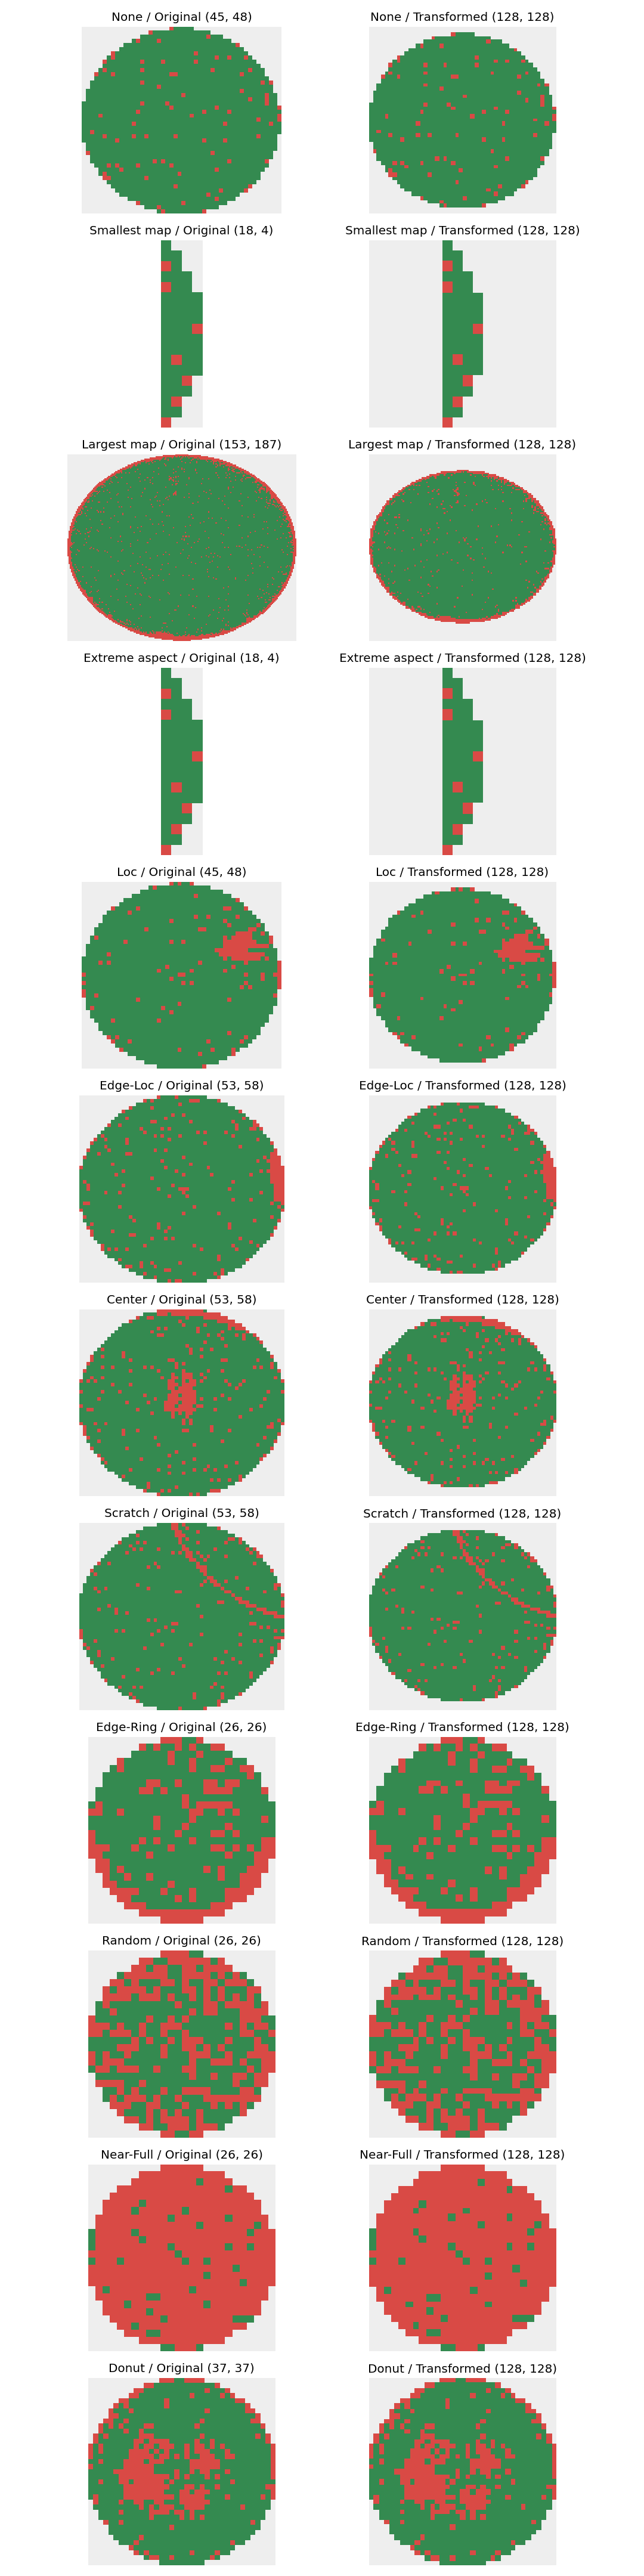

In [8]:
import pandas as pd
from IPython.display import Image, display
from src.wafer_dl.validate_canonical import read_json

# 실제 변환 검사는 별도 실행하고 여기서는 저장 완료된 결과만 확인합니다.
TRANSFORM_CHECK_DIR = project_root / 'reports/wm811k/transform_v1'
if (TRANSFORM_CHECK_DIR / 'SUCCESS.json').is_file():
    completion = read_json(TRANSFORM_CHECK_DIR / 'SUCCESS.json')
    if completion.get('status') != 'transform_check_complete':
        raise ValueError('변환 검사 완료 표식이 아닙니다.')
    transform_report = read_json(TRANSFORM_CHECK_DIR / 'transform_check.json')
    print('검사 상태:', transform_report['status'])
    print('형태 보존 시각 검토는 별도로 필요합니다. 학습 준비 완료가 아닙니다.')
    display(pd.DataFrame(transform_report['classes']))
    display(Image(filename=str(TRANSFORM_CHECK_DIR / 'examples.png')))
else:
    print('저장된 변환 검사 결과가 없습니다. 안내된 명령을 먼저 실행하세요.')

## 9. 실제 전처리·그룹 분할·캐시 결과

1~7절의 EDA는 충돌 제외 전입니다. 이후 실제 분할에서 라벨 충돌 14그룹의 33행(라벨 28·미라벨 5)을 제외했고, 지도학습 대상은 172,922건입니다. 원본 삭제나 임의 재라벨링은 하지 않았습니다.
`split_summary.csv`는 집계표이고 `split_manifest.jsonl`의 `split_group_id`는 연결 그룹, `group_split`은 그룹 배정, `split`은 각 행의 최종 용도입니다. 같은 Lot·동일 맵 관계를 유지하며 약 70/15/15로 나눴습니다.
아래 셀은 저장된 JSON 요약만 읽습니다. 원본 pickle·NPZ·캐시 배열·개별 색인을 읽거나 재분할·캐시 생성·모델 학습을 실행하지 않습니다. Test 클래스 집계는 이미 확정한 분할의 구조 확인이며 Test 예측 성능 평가가 아닙니다.
프로젝트 루트 설정 셀을 먼저 실행하세요. 상세 해석은 [report.md 10~14절](report.md#10-실제-전처리-실행과-데이터-수-변화)을 참고하세요.

In [9]:
import pandas as pd
from IPython.display import display
from src.wafer_dl.validate_canonical import read_json

# ==========================================
# 저장된 분할·캐시 요약만 확인
# - 완료 표식과 분할 프로토콜의 정합성을 확인
# - 숫자 배열이나 Test 이미지를 열지 않고 집계를 표시
# ==========================================
SPLIT_RESULT_DIR = project_root / 'data/splits/wm811k/group_v1'
CACHE_RESULT_DIR = project_root / 'data/processed/wm811k/input_cache/wm_resize_v1'
required_summaries = [SPLIT_RESULT_DIR / 'SUCCESS.json', SPLIT_RESULT_DIR / 'split.json',
                      CACHE_RESULT_DIR / 'SUCCESS.json', CACHE_RESULT_DIR / 'cache.json']
if all(path.is_file() for path in required_summaries):
    split_summary = read_json(SPLIT_RESULT_DIR / 'split.json')
    split_completion = read_json(SPLIT_RESULT_DIR / 'SUCCESS.json')
    cache_summary = read_json(CACHE_RESULT_DIR / 'cache.json')
    cache_completion = read_json(CACHE_RESULT_DIR / 'SUCCESS.json')
    protocol = split_summary.get('split_protocol_id')
    if not (split_summary.get('status') == split_completion.get('status') == 'split_complete'
            and cache_summary.get('status') == cache_completion.get('status') == 'cache_complete'
            and protocol is not None
            and all(item.get('split_protocol_id') == protocol
                    for item in (split_completion, cache_summary, cache_completion))):
        raise ValueError('완료 상태 또는 분할 프로토콜이 일치하지 않습니다. 결과 묶음을 확인하세요.')

    # 고정 클래스 번호 순서로 집계하며 캐시도 같은 매핑인지 확인합니다.
    mapping = split_summary['class_mapping']
    if mapping != cache_summary['class_mapping']:
        raise ValueError('분할과 캐시의 클래스 매핑이 다릅니다.')
    split_table = pd.DataFrame(
        {name: split_summary['class_counts'][name] for name in ('train', 'validation', 'test')},
        index=[mapping[str(index)] for index in range(9)],
    )
    split_table.index.name = '클래스'
    display(split_table)
    split_totals = split_table.sum()
    display(pd.DataFrame({'표본 수': split_totals,
                          '전체 라벨 대상 비율(%)': split_totals / split_totals.sum() * 100}))
    print('충돌 그룹:', split_summary['excluded_conflict_groups'],
          '/ 제외 행:', split_summary['excluded_rows'])
    print('그룹 비중첩 검사:', split_summary['overlap_check_passed'])

    # 준비된 캐시만 표시합니다. Test 분할과 Test 캐시 존재는 별개입니다.
    cache_rows = [{'구간': name, '표본 수': item['rows'], 'shard 수': len(item['shards'])}
                  for name, item in cache_summary['splits'].items()]
    display(pd.DataFrame(cache_rows))
    print('캐시 생성 시 Test 맵 접근:', cache_summary['test_maps_read'])
    print('이번 셀은 저장 집계만 읽었습니다. 배열 무결성 재검사나 첫 배치 재실행이 아닙니다.')
else:
    print('완료된 분할·캐시 요약이 없습니다. 로컬 결과 폴더를 연결하세요. 자동 생성하지 않습니다.')

,train,validation,test
클래스,,,
None,101768,22821,22831
Center,3144,573,574
Donut,439,58,58
Edge-Loc,3653,764,763
Edge-Ring,7685,997,996
Loc,2811,390,389
Near-Full,113,18,18
Random,688,89,89
Scratch,960,117,116


,표본 수,전체 라벨 대상 비율(%)
train,121261,70.124680
validation,25827,14.935636
test,25834,14.939684


충돌 그룹: 14 / 제외 행: 33
그룹 비중첩 검사: True


,구간,표본 수,shard 수
0,train,121261,30
1,validation,25827,7


캐시 생성 시 Test 맵 접근: False
이번 셀은 저장 집계만 읽었습니다. 배열 무결성 재검사나 첫 배치 재실행이 아닙니다.


## 10. 입력 계약 확인 기록과 데이터 전달

2026-10-10 사용자가 공유한 CLI 출력 기준으로 Train·Validation 모두 `dataset_batch_passed`입니다. 아래는 실행 이력이며 노트북 셀 실행으로 새로 검증한 결과는 아닙니다.

| 구간 | 이미지 형태 | 이미지 dtype | 라벨 dtype | Test 맵 접근 |
| --- | --- | --- | --- | --- |
| Train | `[32,2,128,128]` | `torch.float32` | `torch.int64` | 없음 |
| Validation | `[32,2,128,128]` | `torch.float32` | `torch.int64` | 없음 |

- 채널 순서는 불량 마스크(`map==2`)·유효 다이 마스크(`map>0`)입니다. 라벨 0~8은 픽셀 상태 0·1·2와 별개입니다.
- 147,088건 변환 검사에서 불량·유효 영역 전체 소실은 0건이었습니다. 이것이 모든 얇은 선·고리 형태의 동등성을 증명하지는 않습니다.
- 첫 배치 통과는 전체 Epoch·다중 worker 처리량·모델 성능 확인이 아닙니다. 캐시의 `training_ready=false`도 자동 변경되지 않습니다.
- 2026-10-10 시점에는 Test 25,834건 분할은 완료됐지만 캐시는 미준비였습니다. 이후 동결 CNN 평가를 위해 별도 Test 캐시를 준비했고 평가를 1회 수행했으므로 이 메모는 당시 상태로만 읽어야 합니다.
- 캐시 전체(완료 표식·요약·색인·NPY 포함)는 Git 밖에서 전달합니다. 데이터를 받은 환경에서 첫 배치 명령을 다시 확인하며 재분할하지 않습니다.
- 명령과 학습 연결 예시는 [캐시·Dataset 사용법](../../docs/WM811K/CACHE_DATASET.md)을 참고하세요. 실제 코드·설정은 Git으로 공유합니다.
- 전체 EDA에는 분할 전 표본을 사용했습니다.
- 위 상세 집계·표본·그림·경로는 향후 에이전트의 외부 LLM·추적 서비스에 자동 전달하지 않습니다. 노트북 공개 전에는 기존 출력의 데이터 노출도 별도로 점검하세요.

## 11. 튜닝 실험 결과 (Validation)

사용자가 로컬 GPU에서 실행한 학습 39회(초기 비교 18회 + ResNet18+D4 가중치 9회 + SmallWaferCNN+D4 가중치 6회 + 두 모델 학습률 스케줄 6회)와 ResNet18+D4 Validation 재추론의 **저장 결과만** 읽습니다. CNN `scratch0_7` 3회는 미실행입니다. 아래 셀은 학습·재추론·Test 평가를 실행하지 않고 모델도 만들지 않습니다. 해석은 [report.md 15~21절](report.md#15-현재-모델-실험의-범위와-근거)을 따릅니다.

- 이 절의 지표는 Validation 25,827건 기준이며 checkpoint 선택과 조건 비교에 쓰였으므로 일반화 성능이 아닙니다.
- 후보 동결과 최종 Test 결과는 12절에 있습니다. 표에 나오는 `선정 보류`는 집계 도구가 자동 선정을 하지 않는다는 표시이며, 사용자의 후보 동결 결정과 별개입니다.
- 과거 평가 분할과 현재 Test의 표본 겹침은 미확인입니다. 과거 이력만으로 현재 Test가 이미 사용됐다고 단정하지 않으며 완전한 미사용을 보증하지도 않습니다.

프로젝트 루트 설정 셀을 먼저 실행하세요. 이 절의 저장 출력은 설정 셀과 이 절의 셀만 따로 실행해 얻은 것이라 실행 번호가 없습니다. `SAVE_FIGURES=True`일 때만 보고서용 PNG를 새로 저장하며 기존 파일은 덮어쓰지 않습니다.

In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

# ==========================================
# 저장 결과 위치와 표시 기준
# - 결과가 없으면 안내만 하고 다른 경로로 대체하지 않음
# - 클래스 순서·단위는 report.md와 동일
# ==========================================
SAVE_FIGURES = False
RESULT_DIR = project_root / 'reports/wm811k/results'
ERROR_DIR = project_root / 'reports/wm811k/validation_errors/resnet18_d4_v1'
MODEL_DIR = project_root / 'models/wm811k'
FIGURE_DIR = project_root / 'reports/wm811k/figures/model_compare_v1'

SEEDS = [42, 43, 44]
CONDITIONS = {'기준': None, 'cap1_5': 'cap1_5', 'alpha0_75': 'alpha0_75', 'scratch0_7': 'scratch0_7'}
CONDITION_COLORS = dict(zip(CONDITIONS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']))
MODEL_COLORS = {'ResNet18': '#2a78d6', 'SmallWaferCNN': '#eb6834', 'MobileNetV3Small': '#1baf7a'}
mpl.rcParams['font.family'] = 'Malgun Gothic'
mpl.rcParams['axes.unicode_minus'] = False

required_results = [
    RESULT_DIR / 'compare_v2/summary.csv',
    RESULT_DIR / 'compare_v2/runs.csv',
    ERROR_DIR / 'analysis.json',
    ERROR_DIR / 'SUCCESS.json',
]
for name in list(CONDITIONS)[1:]:
    required_results += [RESULT_DIR / f'weight_v1/{name}/runs.csv',
                         RESULT_DIR / f'weight_v1/{name}_vs_baseline/summary.csv',
                         RESULT_DIR / f'weight_v1/{name}_vs_baseline/comparison.json',
                         RESULT_DIR / f'weight_v1/{name}_vs_baseline/SUCCESS.json']
missing_results = [path.relative_to(project_root).as_posix() for path in required_results
                   if not path.is_file()]
results_ready = not missing_results


def read_saved_json(path):
    return json.loads(path.read_text(encoding='utf-8'))


def run_rows(name):
    """조건의 실행별 집계를 seed별 행으로 읽습니다. 기준은 초기 비교의 ResNet18+D4입니다."""
    if name is None:
        runs = pd.read_csv(RESULT_DIR / 'compare_v2/runs.csv')
        return runs[(runs['model_name'] == 'ResNet18') & (runs['augmentation'] == 'd4')]
    return pd.read_csv(RESULT_DIR / f'weight_v1/{name}/runs.csv')


def save_figure(figure, file_name):
    """선택 저장만 수행하고 기존 PNG는 덮어쓰지 않습니다."""
    if not SAVE_FIGURES:
        return
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    target = FIGURE_DIR / file_name
    if target.exists():
        print('기존 그림을 유지합니다:', target.name)
        return
    figure.savefig(target, dpi=150, bbox_inches='tight')


if results_ready:
    print('저장 결과를 찾았습니다. 학습·재추론·Test는 실행하지 않습니다.')
else:
    print('아래 저장 결과가 없어 이 절의 표와 그림을 표시하지 않습니다.')
    print('CSV·모델은 Git에 포함되지 않습니다. 실험을 실행한 환경의 결과를 같은 경로에 두세요.')
    print('실행 방법: docs/WM811K/CACHE_DATASET.md')
    for path in missing_results:
        print(' -', path)

저장 결과를 찾았습니다. 학습·재추론·Test는 실행하지 않습니다.


### 11.1 초기 비교 18회

3모델 × `none`·`d4` × seed 42·43·44입니다. 그림의 작은 점은 seed별 값, 큰 점은 평균, 가로선은 표본표준편차(n=3)입니다. 순서는 Macro-F1 평균이며 통계적 유의성을 뜻하지 않습니다.

,모델,증강,Macro-F1 평균(%),Macro-F1 표준편차(%),Scratch Precision(%),Scratch Recall(%),Random Recall(%),Near-Full Recall(%),Donut Recall(%),파라미터,학습 시간(분),학습 메모리(MiB),추론(ms/표본),추론 메모리(MiB)
0,ResNet18,d4,81.598,0.707,35.526,91.168,75.655,94.444,93.103,11177993,34.209,691.229,0.062,314.692
1,ResNet18,none,79.572,2.869,30.274,90.313,81.273,100.000,77.011,11177993,29.303,690.895,0.057,314.692
2,SmallWaferCNN,d4,79.547,0.503,39.417,96.296,89.888,94.444,85.057,288329,52.574,857.896,0.056,401.112
3,SmallWaferCNN,none,79.457,0.785,54.576,95.157,91.760,96.296,72.989,288329,49.269,857.896,0.065,401.112
4,MobileNetV3Small,d4,75.198,4.954,26.485,85.185,81.648,96.296,89.080,1526937,40.246,420.112,0.069,189.930
5,MobileNetV3Small,none,73.487,3.678,12.433,85.755,82.772,90.741,81.034,1526937,40.574,420.112,0.069,189.930


seed,42,43,44
조건,,,
MobileNetV3Small / d4,69.76,79.45,76.39
MobileNetV3Small / none,71.95,77.68,70.83
ResNet18 / d4,80.88,82.29,81.63
ResNet18 / none,76.29,81.62,80.81
SmallWaferCNN / d4,80.06,79.53,79.05
SmallWaferCNN / none,78.72,79.37,80.28


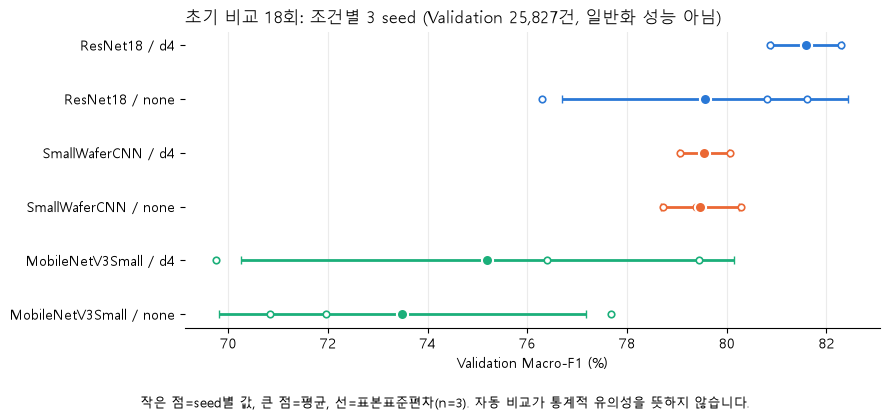

In [ ]:
if results_ready:
    summary = pd.read_csv(RESULT_DIR / 'compare_v2/summary.csv')
    runs = pd.read_csv(RESULT_DIR / 'compare_v2/runs.csv')
    if len(runs) != 18:
        raise ValueError('초기 비교 실행 수가 18회가 아닙니다.')

    # 성능은 %, 시간은 분, 메모리는 MiB로 표시합니다.
    table = pd.DataFrame({
        '모델': summary['model_name'],
        '증강': summary['augmentation'],
        'Macro-F1 평균(%)': summary['macro_f1_mean'] * 100,
        'Macro-F1 표준편차(%)': summary['macro_f1_std'] * 100,
        'Scratch Precision(%)': summary['Scratch_precision_mean'] * 100,
        'Scratch Recall(%)': summary['Scratch_recall_mean'] * 100,
        'Random Recall(%)': summary['Random_recall_mean'] * 100,
        'Near-Full Recall(%)': summary['Near-Full_recall_mean'] * 100,
        'Donut Recall(%)': summary['Donut_recall_mean'] * 100,
        '파라미터': summary['parameter_count'],
        '학습 시간(분)': summary['training_seconds_mean'] / 60,
        '학습 메모리(MiB)': summary['peak_cuda_memory_bytes_mean'] / 2**20,
        '추론(ms/표본)': summary['inference_ms_per_sample_mean'],
        '추론 메모리(MiB)': summary['inference_peak_cuda_memory_bytes_mean'] / 2**20,
    }).sort_values('Macro-F1 평균(%)', ascending=False)
    display(table.round(3).reset_index(drop=True))

    seed_table = runs.assign(조건=runs['model_name'] + ' / ' + runs['augmentation'],
                             macro_f1_pct=runs['macro_f1'] * 100)
    display(seed_table.pivot(index='조건', columns='seed', values='macro_f1_pct').round(2))

    ordered = table.iloc[::-1].reset_index(drop=True)
    figure, axis = plt.subplots(figsize=(9, 4.2))
    for position, row in ordered.iterrows():
        color = MODEL_COLORS[row['모델']]
        values = runs[(runs['model_name'] == row['모델'])
                      & (runs['augmentation'] == row['증강'])]['macro_f1'] * 100
        axis.errorbar(row['Macro-F1 평균(%)'], position, xerr=row['Macro-F1 표준편차(%)'],
                      color=color, linewidth=2, capsize=3, zorder=2)
        axis.scatter(values, [position] * len(values), s=22, facecolor='white',
                     edgecolor=color, linewidth=1.2, zorder=3)
        axis.scatter(row['Macro-F1 평균(%)'], position, s=64, color=color,
                     edgecolor='white', linewidth=1.5, zorder=4)
    axis.set_yticks(range(len(ordered)),
                    [f"{row['모델']} / {row['증강']}" for _, row in ordered.iterrows()])
    axis.set_xlabel('Validation Macro-F1 (%)')
    axis.set_title('초기 비교 18회: 조건별 3 seed (Validation 25,827건, 일반화 성능 아님)', loc='left')
    axis.grid(axis='x', alpha=0.25)
    axis.spines[['top', 'right', 'left']].set_visible(False)
    figure.supxlabel('작은 점=seed별 값, 큰 점=평균, 선=표본표준편차(n=3). 자동 비교가 통계적 유의성을 뜻하지 않습니다.',
                     fontsize=9)
    figure.tight_layout()
    save_figure(figure, 'compare_macro_f1.png')
    plt.show()
    plt.close(figure)

### 11.2 학습 곡선

ResNet18+D4 기준과 가중치 후보의 `training_report.json` 저장 `history`에서 Validation Macro-F1을 읽습니다. 표시한 점은 각 seed의 선택 epoch입니다. 가중치가 달라 Train loss 값은 조건 사이에서 직접 비교하지 않으므로 그리지 않았습니다. 모델 폴더는 Git에 없으므로 없으면 안내만 표시합니다.

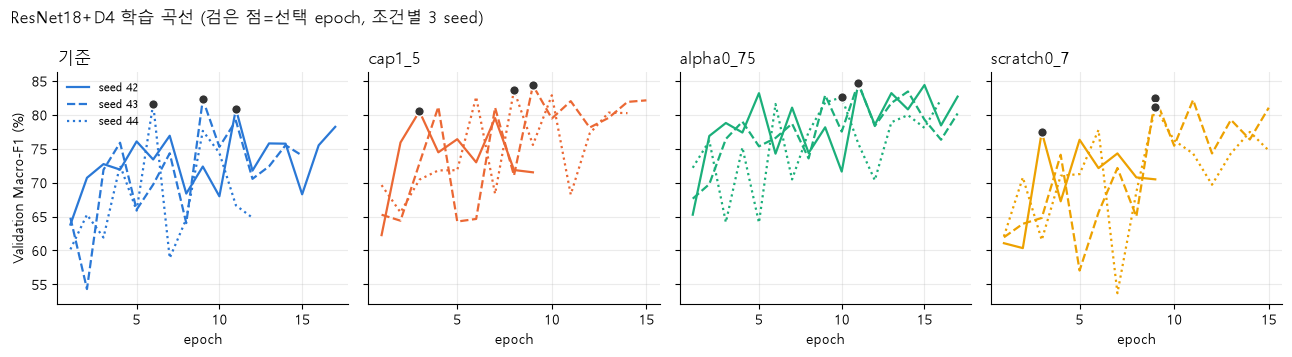

In [ ]:
if results_ready:
    report_paths = {}
    for label, name in CONDITIONS.items():
        root = MODEL_DIR / 'compare_v2' if name is None else MODEL_DIR / 'weight_v1' / name
        for seed in SEEDS:
            report_paths[label, seed] = root / f'ResNet18_d4_seed{seed}' / 'training_report.json'
    absent = [path for path in report_paths.values() if not path.is_file()]
    if absent:
        print('training_report.json이 없어 학습 곡선을 표시하지 않습니다.')
        for path in absent:
            print(' -', path.relative_to(project_root).as_posix())
    else:
        figure, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
        seed_styles = dict(zip(SEEDS, ['-', '--', ':']))
        for axis, label in zip(axes, CONDITIONS):
            for seed in SEEDS:
                report = read_saved_json(report_paths[label, seed])
                epochs = [item['epoch'] for item in report['history']]
                scores = [item['validation']['macro_f1'] * 100 for item in report['history']]
                selected = report['selected_epoch']
                axis.plot(epochs, scores, seed_styles[seed], color=CONDITION_COLORS[label],
                          linewidth=1.6, label=f'seed {seed}')
                axis.scatter(selected, scores[epochs.index(selected)], s=48, color='#333333',
                             zorder=3, edgecolor='white')
            axis.set_title(label, loc='left')
            axis.set_xlabel('epoch')
            axis.grid(alpha=0.25)
            axis.spines[['top', 'right']].set_visible(False)
        axes[0].set_ylabel('Validation Macro-F1 (%)')
        axes[0].legend(frameon=False, fontsize=8)
        figure.suptitle('ResNet18+D4 학습 곡선 (검은 점=선택 epoch, 조건별 3 seed)', x=0.01, ha='left')
        figure.tight_layout()
        save_figure(figure, 'learning_curves.png')
        plt.show()
        plt.close(figure)

### 11.3 ResNet18+D4 Validation 재추론

초기 비교의 세 seed checkpoint로 Validation만 재추론한 결과입니다. 재추론은 학습 횟수에 포함하지 않습니다. `서로 다른 표본`은 고유 표본 수이고 `seed별 건수`는 같은 표본이 반복 예측된 횟수이므로 합산해 독립 표본처럼 읽지 않습니다. 이미지는 선정 표본이며 전체 오류가 아닙니다. 그림은 검사 맵을 3색으로 합성한 것이고, 관찰만으로 라벨 오류나 물리 원인을 확정하지 않습니다. 이미지·범례·선정 기준은 [오분류 보고서](validation_errors/resnet18_d4_v1/report.md)에서 확인합니다.

In [ ]:
if results_ready:
    completion = read_saved_json(ERROR_DIR / 'SUCCESS.json')
    analysis = read_saved_json(ERROR_DIR / 'analysis.json')
    print('상태:', completion['status'], '/ 구간:', completion['split'],
          '/ 혼동행렬 재현 일치:', completion['reproduction_matched'])
    rows = []
    for group in analysis['priority_groups']:
        rows.append({
            '오류 흐름': f"{group['actual_label']} → {group['predicted_label'] or '다른 클래스'}",
            '실제 표본': group['actual_label_samples'],
            '서로 다른 표본': group['distinct_samples'],
            '전 seed 공통': group['samples_in_every_seed'],
            **{f'seed{seed} 건수': group['seed_error_counts'][str(seed)] for seed in SEEDS},
            '그림 선정': group['images']['selected_samples'],
            '그림 생략': group['images']['omitted_samples'],
        })
    display(pd.DataFrame(rows))
    display(pd.DataFrame([analysis['repeats']['samples_by_wrong_seed_count']],
                         index=['서로 다른 표본 수']).rename_axis(columns='오답 seed 수'))

상태: validation_error_analysis_complete / 구간: validation / 혼동행렬 재현 일치: True


,오류 흐름,실제 표본,서로 다른 표본,전 seed 공통,seed42 건수,seed43 건수,seed44 건수,그림 선정,그림 생략
0,Loc → Scratch,390,73,7,21,23,60,24,49
1,None → Scratch,22821,299,24,175,111,133,24,275
2,Random → 다른 클래스,89,37,10,11,17,37,24,13


오답 seed 수,0,1,2,3
서로 다른 표본 수,24542,693,333,259


### 11.4 가중치 후보 9회

세 후보는 모두 ResNet18+D4·같은 seed 3개이며, 기준에서 독립적으로 바꾼 조건입니다. 기준(초기 비교)과 후보의 실행 코드는 다르고 차이 파일은 `train.py`입니다. 판정 참고안은 사용자가 승인한 운영 기준이나 통계적 유의성 판정이 아닙니다. 표의 FN·FP는 3 seed 평균 건수이고 Near-Full은 Validation 18건, Donut은 58건입니다.

,기준,cap1_5,alpha0_75,scratch0_7
Macro-F1 (%),81.60 ± 0.71,82.84 ± 2.04,83.97 ± 1.20,80.39 ± 2.62
Scratch Precision (%),35.53 ± 3.21,33.28 ± 4.06,46.32 ± 6.57,30.70 ± 9.08
Scratch Recall (%),91.17 ± 6.00,87.75 ± 11.67,94.59 ± 3.56,74.36 ± 28.95
Random Recall (%),75.66 ± 15.30,87.27 ± 1.30,87.64 ± 1.95,87.27 ± 6.39
Near-Full Recall (%),94.44 ± 5.56,85.19 ± 3.21,90.74 ± 16.04,90.74 ± 3.21
Donut Recall (%),93.10 ± 2.99,83.91 ± 11.22,92.53 ± 3.59,87.36 ± 8.85


,기준,cap1_5,alpha0_75,scratch0_7
3 seed 평균 건수 (3 seed 합계 순증),,,,
Scratch FP,196.00,206.00 (+30),132.33 (-191),189.67 (-19)
Scratch FN,10.33,14.33 (+12),6.33 (-12),30.00 (+59)
Random FN,21.67,11.33 (-31),11.00 (-32),11.33 (-31)
Near-Full FN,1.00,2.67 (+5),1.67 (+2),1.67 (+2)
Donut FN,4.00,9.33 (+16),4.33 (+1),7.33 (+10)


,조건,참고안 통과 항목,미달 항목,선정 상태,차이 코드 파일
0,cap1_5,2/7,"평균 Scratch Precision 차이(%p), Scratch Precision...",선정 보류,train.py
1,alpha0_75,6/7,Near-Full FN 증가 합계,선정 보류,train.py
2,scratch0_7,1/7,"평균 Macro-F1 차이(%p), 평균 Scratch Precision 차이(%p...",선정 보류,train.py


,cap1_5,alpha0_75,scratch0_7
기준 대비 같은 seed 차이(%p),,,
Macro-F1 seed42,-0.35,3.72,-3.40
Macro-F1 seed43,2.06,2.44,0.26
Macro-F1 seed44,2.02,0.96,-0.49
Scratch Precision seed42,-4.93,12.06,-13.78
Scratch Precision seed43,-2.01,0.64,-4.08
Scratch Precision seed44,0.20,19.67,3.37


,조건,학습 시간 평균(분),학습 시간 표준편차(분),학습 메모리(MiB),추론(ms/표본),추론 메모리(MiB),선택 epoch
0,기준,34.209,3.524,691.229,0.062,314.692,"[11, 9, 6]"
1,cap1_5,28.357,7.654,690.895,0.061,314.692,"[3, 9, 8]"
2,alpha0_75,37.419,1.238,690.895,0.060,314.692,"[11, 11, 10]"
3,scratch0_7,28.784,7.794,690.895,0.063,314.692,"[3, 9, 9]"


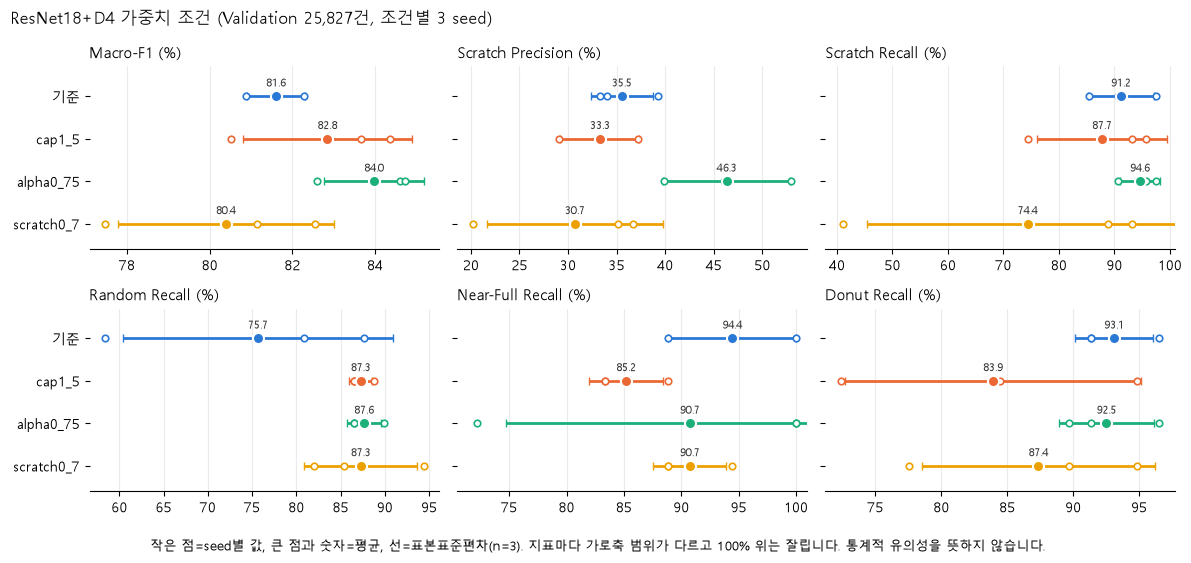

In [ ]:
if results_ready:
    METRICS = [('overall', 'macro_f1', 'Macro-F1'),
               ('Scratch', 'precision', 'Scratch Precision'),
               ('Scratch', 'recall', 'Scratch Recall'),
               ('Random', 'recall', 'Random Recall'),
               ('Near-Full', 'recall', 'Near-Full Recall'),
               ('Donut', 'recall', 'Donut Recall')]
    COUNT_KEYS = [('Scratch', 'fp'), ('Scratch', 'fn'), ('Random', 'fn'),
                  ('Near-Full', 'fn'), ('Donut', 'fn')]

    verdict_rows, comparisons = [], {}
    for label, name in list(CONDITIONS.items())[1:]:
        detail = pd.read_csv(RESULT_DIR / f'weight_v1/{name}_vs_baseline/summary.csv')
        comparisons[label] = detail.set_index(['scope', 'metric'])
        comparison = read_saved_json(RESULT_DIR / f'weight_v1/{name}_vs_baseline/comparison.json')
        if comparison['test_split_used'] is not False or comparison['selected_model'] is not None:
            raise ValueError('대조 결과의 Test 사용·선정 상태를 확인하세요.')
        items = comparison['criteria_results']
        verdict_rows.append({
            '조건': label,
            '참고안 통과 항목': f"{sum(item['passed'] for item in items)}/{len(items)}",
            '미달 항목': ', '.join(item['item'] for item in items if not item['passed']) or '-',
            '선정 상태': comparison['selection_status'],
            '차이 코드 파일': ', '.join(comparison['code']['differing_code_files']),
        })

    baseline = comparisons['cap1_5']
    columns = {'기준': [f"{baseline.loc[(s, m), 'baseline_mean'] * 100:.2f} ± {baseline.loc[(s, m), 'baseline_std'] * 100:.2f}"
                       for s, m, _ in METRICS]}
    for label, frame in comparisons.items():
        columns[label] = [f"{frame.loc[(s, m), 'candidate_mean'] * 100:.2f} ± {frame.loc[(s, m), 'candidate_std'] * 100:.2f}"
                          for s, m, _ in METRICS]
    display(pd.DataFrame(columns, index=[title + ' (%)' for _, _, title in METRICS]))

    counts = {'기준': [f"{baseline.loc[key, 'baseline_mean']:.2f}" for key in COUNT_KEYS]}
    for label, frame in comparisons.items():
        counts[label] = [f"{frame.loc[key, 'candidate_mean']:.2f} ({frame.loc[key, 'difference_sum']:+.0f})"
                         for key in COUNT_KEYS]
    display(pd.DataFrame(counts, index=[f'{scope} {metric.upper()}' for scope, metric in COUNT_KEYS])
            .rename_axis('3 seed 평균 건수 (3 seed 합계 순증)'))

    display(pd.DataFrame(verdict_rows))

    run_values = {label: run_rows(name).set_index('seed') for label, name in CONDITIONS.items()}
    differences = pd.DataFrame({
        label: {f'{title} seed{seed}': (run_values[label].loc[seed, column] - run_values['기준'].loc[seed, column]) * 100
                for column, title in [('macro_f1', 'Macro-F1'), ('Scratch_precision', 'Scratch Precision')]
                for seed in SEEDS}
        for label in list(CONDITIONS)[1:]})
    display(differences.round(2).rename_axis('기준 대비 같은 seed 차이(%p)'))

    cost_rows = []
    for label, rows in run_values.items():
        cost_rows.append({'조건': label,
                          '학습 시간 평균(분)': rows['training_seconds'].mean() / 60,
                          '학습 시간 표준편차(분)': rows['training_seconds'].std() / 60,
                          '학습 메모리(MiB)': rows['peak_cuda_memory_bytes'].mean() / 2**20,
                          '추론(ms/표본)': rows['inference_ms_per_sample'].mean(),
                          '추론 메모리(MiB)': rows['inference_peak_cuda_memory_bytes'].mean() / 2**20,
                          '선택 epoch': rows['selected_epoch'].tolist()})
    display(pd.DataFrame(cost_rows).round(3))

    figure, axes = plt.subplots(2, 3, figsize=(12, 5.6), sharey=True)
    labels = list(CONDITIONS)
    for axis, (scope, metric, title) in zip(axes.flat, METRICS):
        column = 'macro_f1' if scope == 'overall' else f'{scope}_{metric}'
        for position, label in enumerate(reversed(labels)):
            values = run_values[label][column] * 100
            color = CONDITION_COLORS[label]
            axis.errorbar(values.mean(), position, xerr=values.std(), color=color,
                          linewidth=2, capsize=3, zorder=2)
            axis.scatter(values, [position] * len(values), s=22, facecolor='white',
                         edgecolor=color, linewidth=1.2, zorder=3)
            axis.scatter(values.mean(), position, s=64, color=color,
                         edgecolor='white', linewidth=1.5, zorder=4)
            axis.annotate(f'{values.mean():.1f}', (values.mean(), position), xytext=(0, 7),
                          textcoords='offset points', ha='center', fontsize=8, color='#333333')
        axis.set_yticks(range(len(labels)), list(reversed(labels)))
        axis.set_ylim(-0.6, len(labels) - 0.3)
        # 평균+표준편차가 100%를 넘어도 지표 범위 밖은 표시하지 않습니다.
        axis.set_xlim(right=min(axis.get_xlim()[1], 101))
        axis.set_title(f'{title} (%)', loc='left', fontsize=11)
        axis.grid(axis='x', alpha=0.25)
        axis.spines[['top', 'right', 'left']].set_visible(False)
    figure.suptitle('ResNet18+D4 가중치 조건 (Validation 25,827건, 조건별 3 seed)', x=0.01, ha='left')
    figure.supxlabel('작은 점=seed별 값, 큰 점과 숫자=평균, 선=표본표준편차(n=3). 지표마다 가로축 범위가 다르고 100% 위는 잘립니다. 통계적 유의성을 뜻하지 않습니다.',
                     fontsize=9)
    figure.tight_layout()
    save_figure(figure, 'weight_metrics.png')
    plt.show()
    plt.close(figure)

### 11.5 ResNet18 가중치 단계의 판단과 제약

- 이 단계에서 가장 유망한 설정은 ResNet18+D4·`alpha0_75`였지만 Near-Full FN 순증 2회로 판정 참고안 1회를 넘었고, 세 후보 모두 참고안 전체를 통과하지 못했습니다.
- 최고 seed 하나를 골라 모델 성능으로 발표하지 않습니다.
- 초기 기준과 후보의 코드 차이는 `train.py`입니다. 기본 가중치 계산의 합성 동등성은 확인했지만 실제 신구 학습의 동등성은 측정하지 않았습니다.
- WM-811K는 다이별 검사 결과 맵이며 광학 사진이 아닙니다. `None`은 데이터셋 라벨이며 미라벨이나 최종 양품이 아닙니다.

### 11.6 SmallWaferCNN+D4 가중치 후보 6회와 학습률 스케줄 6회

세 표 모두 Validation 25,827건의 저장 대조 결과이며 Test를 쓰지 않았습니다. CNN `scratch0_7` 3회는 **미실행**입니다. 가중치 후보는 초기 CNN+D4를 기준으로 하나씩 바꾼 독립 조건이고, 스케줄 후보는 모델별 고정 학습률 `alpha0_75`를 기준으로 `ReduceLROnPlateau`만 더한 조건입니다. 기준과 후보의 코드는 `train.py`가 다르며, 고정 학습률 경로의 계산 동등성은 합성 검증 범위이고 실제 신구 학습의 동등성은 측정하지 않았습니다.

In [ ]:
TUNING_SOURCES = {
    'CNN cap1_5': RESULT_DIR / 'weight_cnn_v1/cap1_5_vs_baseline',
    'CNN alpha0_75': RESULT_DIR / 'weight_cnn_v1/alpha0_75_vs_baseline',
    'CNN 스케줄': RESULT_DIR / 'lr_v1/SmallWaferCNN/plateau_alpha0_75_vs_baseline',
    'ResNet18 스케줄': RESULT_DIR / 'lr_v1/ResNet18/plateau_alpha0_75_vs_baseline',
}
tuning_missing = [path.relative_to(project_root).as_posix() for path in TUNING_SOURCES.values()
                  if not (path / 'summary.csv').is_file() or not (path / 'comparison.json').is_file()]
if tuning_missing:
    print('아래 저장 결과가 없어 이 표를 표시하지 않습니다. CSV는 Git에 포함되지 않습니다.')
    for path in tuning_missing:
        print(' -', path)
else:
    TUNING_METRICS = [('overall', 'macro_f1', 'Macro-F1'),
                      ('Scratch', 'precision', 'Scratch Precision'),
                      ('Scratch', 'recall', 'Scratch Recall'),
                      ('Random', 'recall', 'Random Recall'),
                      ('Near-Full', 'recall', 'Near-Full Recall'),
                      ('Donut', 'recall', 'Donut Recall')]
    frames = {label: pd.read_csv(path / 'summary.csv').set_index(['scope', 'metric'])
              for label, path in TUNING_SOURCES.items()}
    for label, path in TUNING_SOURCES.items():
        comparison = read_saved_json(path / 'comparison.json')
        if comparison['test_split_used'] is not False or comparison['selected_model'] is not None:
            raise ValueError('대조 결과의 Test 사용·선정 상태를 확인하세요: ' + label)

    def tuning_cell(frame, scope, metric, side):
        return (f"{frame.loc[(scope, metric), side + '_mean'] * 100:.2f} ± "
                f"{frame.loc[(scope, metric), side + '_std'] * 100:.2f}")

    names = [name for _, _, name in TUNING_METRICS]
    display(pd.DataFrame({
        'CNN 기준(alpha 1)': [tuning_cell(frames['CNN cap1_5'], s, m, 'baseline') for s, m, _ in TUNING_METRICS],
        'CNN cap1_5': [tuning_cell(frames['CNN cap1_5'], s, m, 'candidate') for s, m, _ in TUNING_METRICS],
        'CNN alpha0_75': [tuning_cell(frames['CNN alpha0_75'], s, m, 'candidate') for s, m, _ in TUNING_METRICS],
    }, index=names).rename_axis('Validation 지표(%)'))
    for model, label in (('SmallWaferCNN', 'CNN 스케줄'), ('ResNet18', 'ResNet18 스케줄')):
        display(pd.DataFrame({
            f'{model} 고정 lr': [tuning_cell(frames[label], s, m, 'baseline') for s, m, _ in TUNING_METRICS],
            f'{model} ReduceLROnPlateau': [tuning_cell(frames[label], s, m, 'candidate') for s, m, _ in TUNING_METRICS],
        }, index=names).rename_axis('Validation 지표(%)'))

,CNN 기준(alpha 1),CNN cap1_5,CNN alpha0_75
Validation 지표(%),,,
Macro-F1,79.55 ± 0.50,82.28 ± 2.15,83.08 ± 0.93
Scratch Precision,39.42 ± 4.00,53.24 ± 5.95,61.02 ± 4.94
Scratch Recall,96.30 ± 0.99,91.74 ± 5.69,90.03 ± 3.56
Random Recall,89.89 ± 1.12,87.27 ± 2.83,91.01 ± 1.12
Near-Full Recall,94.44 ± 5.56,92.59 ± 3.21,92.59 ± 8.49
Donut Recall,85.06 ± 5.54,72.41 ± 3.45,81.03 ± 4.56


,SmallWaferCNN 고정 lr,SmallWaferCNN ReduceLROnPlateau
Validation 지표(%),,
Macro-F1,83.08 ± 0.93,82.94 ± 0.67
Scratch Precision,61.02 ± 4.94,61.38 ± 3.86
Scratch Recall,90.03 ± 3.56,92.88 ± 2.75
Random Recall,91.01 ± 1.12,92.13 ± 1.12
Near-Full Recall,92.59 ± 8.49,94.44 ± 0.00
Donut Recall,81.03 ± 4.56,82.18 ± 3.98


,ResNet18 고정 lr,ResNet18 ReduceLROnPlateau
Validation 지표(%),,
Macro-F1,83.97 ± 1.20,84.53 ± 1.16
Scratch Precision,46.32 ± 6.57,52.63 ± 21.53
Scratch Recall,94.59 ± 3.56,92.02 ± 8.65
Random Recall,87.64 ± 1.95,88.76 ± 1.95
Near-Full Recall,90.74 ± 16.04,79.63 ± 19.51
Donut Recall,92.53 ± 3.59,87.36 ± 6.05


## 12. 후보 동결과 최종 Test 결과

사용자는 Test를 보기 전에 Validation 결과로 **종합후보 ResNet18**(D4·alpha0.75·상한10·Scratch계수1·고정 lr 0.001)과 **비교후보 SmallWaferCNN**(같은 D4·가중치, `ReduceLROnPlateau`)을 지정해 각 3 seed, 합계 6개 checkpoint를 동결했습니다. 이 절은 그 뒤 실행된 최종 평가의 저장 결과만 읽으며, 학습·추론·Test 재평가·배열 처리를 호출하지 않습니다.

- 예정된 하나의 최종 평가 세션에서 동결 모델 상태 6개를 같은 Test 25,834행으로 각각 평가했습니다. 전체 Test 접근이 1회라는 뜻이 아니며, 표본이 6배로 늘어난 것도 아닙니다.
- 두 모델의 학습률 스케줄이 달라 구조만의 비교가 아니라 선정된 튜닝 구성의 비교입니다. Test 결과로 모델·설정·seed를 다시 고르지 않습니다.
- 과거 평가 분할과 현재 Test의 표본 겹침은 미확인입니다. 과거 이력만으로 현재 Test가 이미 사용됐다고 단정하지 않으며, 완전한 미사용을 보증하지도 않습니다.
- `reports/wm811k/final_test_v1/comparison/`의 CSV는 Git에 포함되지 않습니다. 없으면 안내만 표시하고 다른 결과로 대체하지 않습니다.

저장 출력은 프로젝트 설정 셀과 11절 설정 셀, 11.6·12절 셀만 별도 Python 3.12 프로세스에서 실행해 넣은 것이라 실행 번호가 없습니다. 전체 노트북을 재실행한 결과가 아닙니다. `FINAL_SAVE_FIGURES=True`일 때만 PNG를 새로 저장하고 기존 파일은 덮어쓰지 않습니다.

In [ ]:
import hashlib

# ==========================================
# 최종 평가 저장 결과 확인 (읽기 전용)
# - 완료 표식·해시·실행 수를 대조한 뒤에만 표와 그림을 만듦
# - 평가기·Dataset·모델을 불러오지 않음
# ==========================================
FINAL_SAVE_FIGURES = False
FINAL_DIR = project_root / 'reports/wm811k/final_test_v1'
FREEZE_DIR = project_root / 'reports/wm811k/final_freeze_v1'
COMPARISON_DIR = FINAL_DIR / 'comparison'
FINAL_FIGURE_DIR = project_root / 'reports/wm811k/figures/final_test_v1'
FINAL_MODELS = ['ResNet18', 'SmallWaferCNN']
FINAL_COLORS = {'ResNet18': '#2a78d6', 'SmallWaferCNN': '#eb6834'}
CLASS_ORDER = ['None', 'Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-Full', 'Random', 'Scratch']
COMPARISON_FILES = ['comparison.json', 'comparison.md', 'confusion_matrices.csv', 'per_class.csv',
                    'runs.csv', 'seed_differences.csv', 'summary.csv']


def file_sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def save_final_figure(figure, file_name):
    '''선택 저장만 수행하고 기존 PNG는 덮어쓰지 않습니다.'''
    if not FINAL_SAVE_FIGURES:
        return
    FINAL_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    target = FINAL_FIGURE_DIR / file_name
    if target.exists():
        print('기존 그림을 유지합니다:', target.name)
        return
    figure.savefig(target, dpi=150, bbox_inches='tight')


final_required = [COMPARISON_DIR / name for name in ['SUCCESS.json', *COMPARISON_FILES]]
final_required += [FINAL_DIR / 'session.json', FINAL_DIR / 'attempts.jsonl', FREEZE_DIR / 'freeze.json']
final_missing = [path.relative_to(project_root).as_posix() for path in final_required if not path.is_file()]
final_ready = not final_missing

if not final_ready:
    print('아래 최종 평가 결과가 없어 이 절의 표와 그림을 표시하지 않습니다.')
    print('CSV는 Git에 포함되지 않습니다. 평가를 실행한 환경의 결과를 같은 경로에 두세요.')
    for path in final_missing:
        print(' -', path)
else:
    completion = read_saved_json(COMPARISON_DIR / 'SUCCESS.json')
    if completion['status'] != 'final_test_comparison_complete':
        raise ValueError('최종 비교가 완료 상태가 아닙니다.')
    for name in COMPARISON_FILES:
        if file_sha256(COMPARISON_DIR / name) != completion['artifacts'][name]:
            raise ValueError('완료 기록과 파일이 다릅니다: ' + name)

    final_session = read_saved_json(FINAL_DIR / 'session.json')
    final_freeze = read_saved_json(FREEZE_DIR / 'freeze.json')
    final_attempts = [json.loads(line) for line in
                      (FINAL_DIR / 'attempts.jsonl').read_text(encoding='utf-8').splitlines()]
    if file_sha256(FREEZE_DIR / 'freeze.json') != final_session['freeze_sha256']:
        raise ValueError('동결 명세가 평가 세션과 다릅니다.')

    # 클래스 이름 'None'이 결측으로 읽히지 않도록 빈칸만 결측으로 둡니다.
    def read_final_csv(name):
        return pd.read_csv(COMPARISON_DIR / name, keep_default_na=False, na_values=[''])

    final_runs = read_final_csv('runs.csv')
    final_summary = read_final_csv('summary.csv')
    final_classes = read_final_csv('per_class.csv')
    final_differences = read_final_csv('seed_differences.csv')
    final_confusion = read_final_csv('confusion_matrices.csv')
    frozen_ids = {run['artifacts_sha256']['best_model.pt']
                  for item in final_freeze['candidates'] for run in item['runs']}
    if len(final_runs) != 6 or set(final_runs['checkpoint_sha256']) != frozen_ids:
        raise ValueError('최종 평가가 동결 checkpoint 6개와 일치하지 않습니다.')
    started = [item['run'] for item in final_attempts if item['event'] == 'started']
    finished = [item['run'] for item in final_attempts if item['event'] == 'complete']
    if len(started) != 6 or len(set(started)) != 6 or sorted(started) != sorted(finished) or \
            any(item['event'] == 'failed' for item in final_attempts):
        raise ValueError('평가 시도 기록이 실행별 1회 완료가 아닙니다.')
    print('최종 평가 저장 결과를 확인했습니다. 학습·추론·Test는 실행하지 않습니다.')
    print('checkpoint:', len(final_runs), '/ Test 행:', final_session['test_cache']['test_rows'],
          '/ 실행별 시도 1회 / 실패 0건')

최종 평가 저장 결과를 확인했습니다. 학습·추론·Test는 실행하지 않습니다.
checkpoint: 6 / Test 행: 25834 / 실행별 시도 1회 / 실패 0건


### 12.1 Validation과 Test의 Macro-F1

작은 표식은 seed별 값, 큰 표식은 평균, 선은 표본표준편차(n=3)입니다. seed 3개의 변동을 보여 줄 뿐 신뢰구간이나 통계적 유의성이 아닙니다. Validation은 조건 선택에 쓰였으므로 두 값의 차이를 일반화 간격으로 단정하지 않습니다.

,모델,seed,선택 epoch,Validation Macro-F1(%),Test Macro-F1(%)
0,ResNet18,42,11,84.60,84.87
1,ResNet18,43,11,84.73,85.29
2,ResNet18,44,10,82.59,84.16
3,SmallWaferCNN,42,15,82.69,82.54
4,SmallWaferCNN,43,11,83.69,82.82
5,SmallWaferCNN,44,13,82.43,82.78


,모델,Macro-F1(%),Accuracy(%),Macro-Recall(%),Macro-Precision(%)
0,ResNet18,84.77 ± 0.57,97.55 ± 0.20,92.51 ± 0.16,80.54 ± 1.62
1,SmallWaferCNN,82.71 ± 0.15,97.13 ± 0.10,87.66 ± 1.11,79.39 ± 1.07


,macro_f1,accuracy,macro_recall
"같은 seed 차이(%p, ResNet18-CNN)",,,
42,2.33,0.69,3.67
43,2.47,0.29,5.11
44,1.37,0.25,5.75


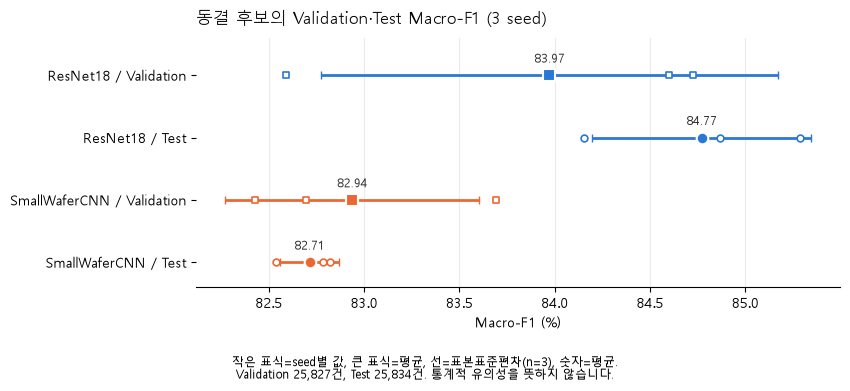

In [ ]:
if final_ready:
    rows = []
    for item in final_freeze['candidates']:
        model = item['model_name']
        for run in item['runs']:
            test_score = final_runs[(final_runs['model_name'] == model)
                                    & (final_runs['seed'] == run['seed'])]['macro_f1'].iloc[0]
            rows.append({'모델': model, 'seed': run['seed'], '선택 epoch': run['selected_epoch'],
                         'Validation Macro-F1(%)': run['validation_macro_f1'] * 100,
                         'Test Macro-F1(%)': test_score * 100})
    validation_test = pd.DataFrame(rows)
    display(validation_test.round(2))

    overall = final_summary[final_summary['scope'] == 'all'].set_index('model_name')

    def mean_std(model, key):
        return f"{overall.loc[model, key + '_mean'] * 100:.2f} ± {overall.loc[model, key + '_std'] * 100:.2f}"

    display(pd.DataFrame({
        '모델': FINAL_MODELS,
        'Macro-F1(%)': [mean_std(m, 'macro_f1') for m in FINAL_MODELS],
        'Accuracy(%)': [mean_std(m, 'accuracy') for m in FINAL_MODELS],
        'Macro-Recall(%)': [mean_std(m, 'macro_recall') for m in FINAL_MODELS],
        'Macro-Precision(%)': [mean_std(m, 'macro_precision') for m in FINAL_MODELS],
    }))
    display((final_differences.set_index('seed')[['macro_f1', 'accuracy', 'macro_recall']] * 100)
            .round(2).rename_axis('같은 seed 차이(%p, ResNet18-CNN)'))

    figure, axis = plt.subplots(figsize=(8.6, 3.9))
    positions = {('ResNet18', 'Validation'): 3, ('ResNet18', 'Test'): 2,
                 ('SmallWaferCNN', 'Validation'): 1, ('SmallWaferCNN', 'Test'): 0}
    columns = {'Validation': 'Validation Macro-F1(%)', 'Test': 'Test Macro-F1(%)'}
    for (model, split), position in positions.items():
        values = validation_test.loc[validation_test['모델'] == model, columns[split]]
        color = FINAL_COLORS[model]
        marker = 'o' if split == 'Test' else 's'
        axis.errorbar(values.mean(), position, xerr=values.std(ddof=1), color=color,
                      linewidth=2, capsize=3, zorder=2)
        axis.scatter(values, [position] * len(values), s=24, marker=marker, facecolor='white',
                     edgecolor=color, linewidth=1.2, zorder=3)
        axis.scatter(values.mean(), position, s=70, marker=marker, color=color,
                     edgecolor='white', linewidth=1.5, zorder=4)
        axis.annotate(f'{values.mean():.2f}', (values.mean(), position), xytext=(0, 9),
                      textcoords='offset points', ha='center', fontsize=9, color='#333333')
    axis.set_yticks(list(positions.values()), [f'{m} / {s}' for m, s in positions])
    axis.set_ylim(-0.4, 3.6)
    axis.set_xlabel('Macro-F1 (%)')
    axis.set_title('동결 후보의 Validation·Test Macro-F1 (3 seed)', loc='left', pad=10)
    axis.grid(axis='x', alpha=0.25)
    axis.spines[['top', 'right', 'left']].set_visible(False)
    figure.supxlabel('작은 표식=seed별 값, 큰 표식=평균, 선=표본표준편차(n=3), 숫자=평균.\n'
                     'Validation 25,827건, Test 25,834건. 통계적 유의성을 뜻하지 않습니다.', fontsize=8.5)
    figure.tight_layout()
    save_final_figure(figure, 'validation_test_macro_f1.png')
    plt.show()
    plt.close(figure)

### 12.2 Test 클래스별 지표

3 seed 평가의 평균·표본표준편차입니다. FP·FN은 seed별 건수의 평균이며 합산 건수가 아닙니다. `support`는 Test의 실제 표본 수로, Near-Full 18건·Donut 58건은 1건이 각각 약 5.6%p, 1.7%p를 움직입니다. `None`은 데이터셋의 무패턴 라벨이며 미라벨이나 최종 양품 판정이 아닙니다.

,모델,클래스,support,Precision(%),Recall(%),F1(%),FP(평균 건),FN(평균 건)
0,ResNet18,None,22831,99.57 ± 0.08,98.46 ± 0.31,99.01 ± 0.14,96.3 ± 18.4,351.3 ± 71.6
1,ResNet18,Center,574,96.86 ± 1.20,90.42 ± 3.31,93.49 ± 1.37,17.0 ± 7.0,55.0 ± 19.0
2,ResNet18,Donut,58,81.37 ± 4.43,91.38 ± 2.99,85.98 ± 1.09,12.3 ± 3.8,5.0 ± 1.7
3,ResNet18,Edge-Loc,763,81.97 ± 6.81,86.81 ± 2.69,84.14 ± 2.47,151.0 ± 75.8,100.7 ± 20.5
4,ResNet18,Edge-Ring,996,96.81 ± 0.92,93.17 ± 0.35,94.95 ± 0.28,30.7 ± 9.3,68.0 ± 3.5
5,ResNet18,Loc,389,73.17 ± 4.89,89.55 ± 2.19,80.45 ± 2.85,129.3 ± 33.3,40.7 ± 8.5
6,ResNet18,Near-Full,18,81.30 ± 18.97,96.30 ± 6.42,86.90 ± 9.16,5.0 ± 5.6,0.7 ± 1.2
7,ResNet18,Random,89,70.31 ± 4.13,88.76 ± 1.12,78.40 ± 2.12,33.7 ± 6.8,10.0 ± 1.0
8,ResNet18,Scratch,116,43.51 ± 11.63,97.70 ± 0.50,59.61 ± 10.69,158.7 ± 64.5,2.7 ± 0.6
9,SmallWaferCNN,None,22831,99.47 ± 0.12,98.63 ± 0.21,99.05 ± 0.07,120.0 ± 28.2,312.3 ± 47.9


model_name,ResNet18,SmallWaferCNN
Scratch 오탐의 실제 클래스 (seed 평균 건수),,
None,123.7,53.3
Center,1.7,1.3
Donut,0.7,3.7
Edge-Loc,6.3,4.3
Edge-Ring,18.7,1.3
Loc,7.0,7.3
Near-Full,0.0,0.0
Random,0.7,0.3


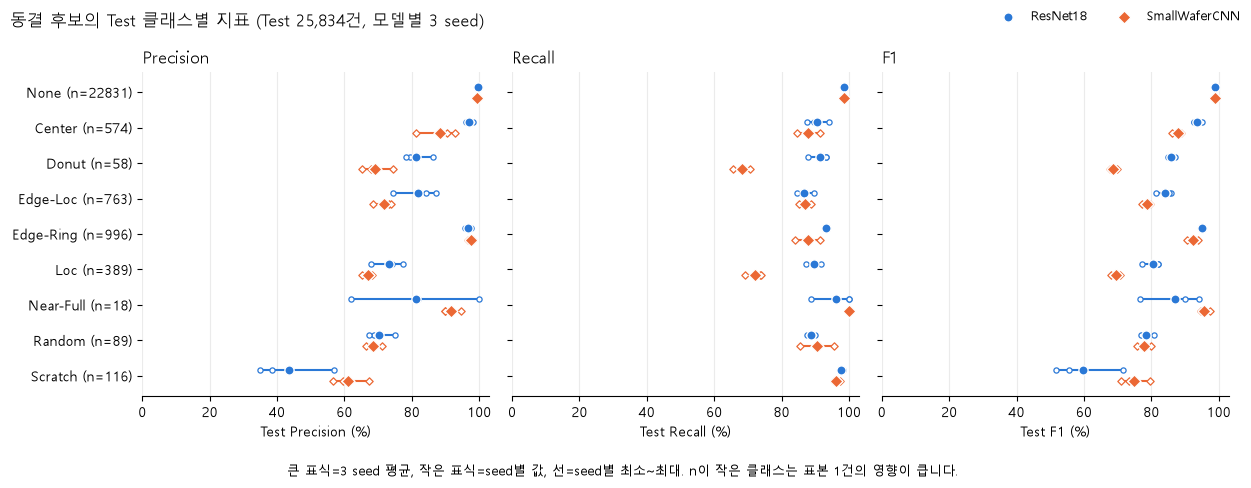

In [ ]:
if final_ready:
    class_summary = final_summary[final_summary['scope'] != 'all']
    rows = []
    for model in FINAL_MODELS:
        for name in CLASS_ORDER:
            row = class_summary[(class_summary['model_name'] == model)
                                & (class_summary['scope'] == name)].iloc[0]
            rows.append({
                '모델': model, '클래스': name, 'support': int(row['support']),
                'Precision(%)': f"{row['precision_mean'] * 100:.2f} ± {row['precision_std'] * 100:.2f}",
                'Recall(%)': f"{row['recall_mean'] * 100:.2f} ± {row['recall_std'] * 100:.2f}",
                'F1(%)': f"{row['f1_mean'] * 100:.2f} ± {row['f1_std'] * 100:.2f}",
                'FP(평균 건)': f"{row['false_positive_mean']:.1f} ± {row['false_positive_std']:.1f}",
                'FN(평균 건)': f"{row['false_negative_mean']:.1f} ± {row['false_negative_std']:.1f}",
            })
    display(pd.DataFrame(rows))

    scratch_sources = (final_confusion[(final_confusion['predicted_class'] == 'Scratch')
                                       & (final_confusion['true_class'] != 'Scratch')]
                       .groupby(['model_name', 'true_class'])['count'].mean().unstack(0)
                       .reindex(CLASS_ORDER[:-1])[FINAL_MODELS])
    display(scratch_sources.round(1).rename_axis('Scratch 오탐의 실제 클래스 (seed 평균 건수)'))

    figure, axes = plt.subplots(1, 3, figsize=(12.5, 4.8), sharey=True)
    positions = {name: len(CLASS_ORDER) - 1 - index for index, name in enumerate(CLASS_ORDER)}
    supports = class_summary.drop_duplicates('scope').set_index('scope')['support']
    for axis, (metric, title) in zip(axes, [('precision', 'Precision'), ('recall', 'Recall'), ('f1', 'F1')]):
        for offset, model, marker in ((0.16, 'ResNet18', 'o'), (-0.16, 'SmallWaferCNN', 'D')):
            color = FINAL_COLORS[model]
            group = final_classes[final_classes['model_name'] == model]
            for name, position in positions.items():
                values = group.loc[group['class_name'] == name, metric] * 100
                axis.plot([values.min(), values.max()], [position + offset] * 2, color=color,
                          linewidth=1.5, zorder=2)
                axis.scatter(values, [position + offset] * len(values), s=14, marker=marker,
                             facecolor='white', edgecolor=color, linewidth=0.9, zorder=3)
                axis.scatter(values.mean(), position + offset, s=44, marker=marker, color=color,
                             edgecolor='white', linewidth=1, zorder=4,
                             label=model if name == 'None' else None)
        axis.set_title(title, loc='left')
        axis.set_xlabel(f'Test {title} (%)')
        axis.set_xlim(0, 103)
        axis.grid(axis='x', alpha=0.25)
        axis.spines[['top', 'right', 'left']].set_visible(False)
    axes[0].set_yticks(list(positions.values()),
                       [f'{name} (n={int(supports[name])})' for name in positions])
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, frameon=False, fontsize=9, ncol=2, loc='upper right')
    figure.suptitle('동결 후보의 Test 클래스별 지표 (Test 25,834건, 모델별 3 seed)', x=0.01, ha='left')
    figure.supxlabel('큰 표식=3 seed 평균, 작은 표식=seed별 값, 선=seed별 최소~최대. '
                     'n이 작은 클래스는 표본 1건의 영향이 큽니다.', fontsize=9)
    figure.tight_layout()
    save_final_figure(figure, 'test_class_metrics.png')
    plt.show()
    plt.close(figure)

### 12.3 Test 혼동행렬

각 seed의 혼동행렬을 실제 클래스별 행 합계로 나눠 %로 바꾼 뒤 3 seed를 단순 평균했습니다. 대각선은 Recall입니다. 건수를 합산한 행렬이 아니므로 표본 수가 늘어난 것처럼 읽지 않습니다. seed별 원본 건수는 [comparison.md](final_test_v1/comparison/comparison.md)에 있습니다. 0.05% 미만 칸은 표시를 생략했습니다.

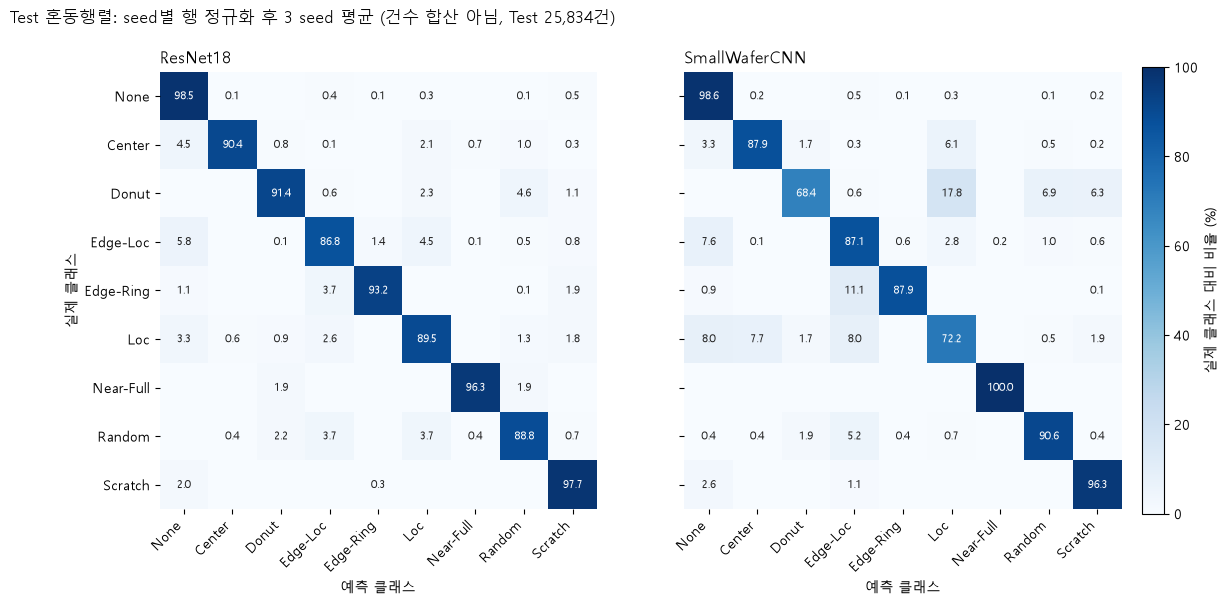

In [ ]:
if final_ready:
    figure, axes = plt.subplots(1, 2, figsize=(13, 5.8), sharey=True)
    for axis, model in zip(axes, FINAL_MODELS):
        matrices = []
        for seed in SEEDS:
            frame = final_confusion[(final_confusion['model_name'] == model)
                                    & (final_confusion['seed'] == seed)]
            table = frame.pivot(index='true_class', columns='predicted_class', values='count') \
                .reindex(index=CLASS_ORDER, columns=CLASS_ORDER)
            if table.to_numpy().sum() != final_session['test_cache']['test_rows']:
                raise ValueError('혼동행렬 합계가 Test 행 수와 다릅니다.')
            matrices.append(table.div(table.sum(axis=1), axis=0).to_numpy() * 100)
        average = np.mean(matrices, axis=0)
        image = axis.imshow(average, cmap='Blues', vmin=0, vmax=100)
        for row in range(len(CLASS_ORDER)):
            for column in range(len(CLASS_ORDER)):
                value = average[row, column]
                if value >= 0.05:
                    axis.text(column, row, f'{value:.1f}', ha='center', va='center', fontsize=8,
                              color='white' if value >= 55 else '#222222')
        axis.set_xticks(range(len(CLASS_ORDER)), CLASS_ORDER, rotation=45, ha='right')
        axis.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
        axis.set_xlabel('예측 클래스')
        axis.set_title(model, loc='left')
        axis.spines[:].set_visible(False)
    axes[0].set_ylabel('실제 클래스')
    colorbar = figure.colorbar(image, ax=list(axes), fraction=0.025, pad=0.02)
    colorbar.set_label('실제 클래스 대비 비율 (%)')
    figure.suptitle('Test 혼동행렬: seed별 행 정규화 후 3 seed 평균 (건수 합산 아님, Test 25,834건)',
                    x=0.01, ha='left')
    save_final_figure(figure, 'test_confusion_normalized.png')
    plt.show()
    plt.close(figure)

### 12.4 평가 시간

`inference_seconds`는 평가 루프 전체 시간입니다. Dataset의 표본별 읽기·채널 변환, DataLoader, 장치 전송, 혼동행렬 집계를 포함하므로 순수 GPU 커널 시간이 아닙니다. 16절의 추론 시간은 미리 GPU에 올린 Validation 640표본을 반복한 마이크로벤치마크라 측정 구간이 다르며, 두 값을 직접 비교하지 않습니다.

In [ ]:
if final_ready:
    table = final_runs[['model_name', 'seed', 'device', 'batch_size', 'test_rows', 'inference_seconds']].copy()
    table['ms/표본(평가 루프)'] = table['inference_seconds'] * 1000 / table['test_rows']
    display(table.round(3).rename(columns={'inference_seconds': '평가 루프 시간(초)'}))

,model_name,seed,device,batch_size,test_rows,평가 루프 시간(초),ms/표본(평가 루프)
0,ResNet18,42,cuda,64,25834,6.093,0.236
1,ResNet18,43,cuda,64,25834,5.780,0.224
2,ResNet18,44,cuda,64,25834,5.741,0.222
3,SmallWaferCNN,42,cuda,64,25834,5.755,0.223
4,SmallWaferCNN,43,cuda,64,25834,5.673,0.220
5,SmallWaferCNN,44,cuda,64,25834,5.623,0.218


### 12.5 종합 결론과 한계

- Validation으로 선정·동결한 ResNet18 종합후보와 SmallWaferCNN 비교후보의 최종 평가를 마쳤습니다. 수치와 해석은 [report.md 22~23절](report.md#22-최종-test-결과)을 따릅니다.
- ResNet18은 평균 Macro-F1이 세 seed 모두 높았지만 Scratch Precision이 낮습니다. SmallWaferCNN은 Macro-F1이 낮아도 Scratch 오탐이 적고 Random·Near-Full Recall 평균이 더 높습니다. 모든 클래스에서 앞서는 모델은 없습니다.
- 같은 Test를 seed별로 반복 평가한 값이며 통계적 유의성을 검정하지 않았습니다. 미래 또는 현장 성능을 보장하지 않습니다.
- 평가 대상은 seed 3개 묶음입니다. 배포 checkpoint 하나를 새로 고르지 않았고 운영 배포도 하지 않았습니다.
- WM-811K는 다이별 검사 결과 맵이며 광학 사진이 아닙니다. D4의 방향 무관 가정(notch·장비 방향)은 확인이 남아 있습니다.